<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
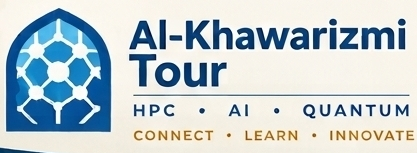
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · WEEK-2 TEAM CHALLENGE NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">The Cholesky Speed Run — from nested loops to vendor speed, in Julia</h1>
<p style="color:#e6eef8;margin:0;">Chapter 0: a working baseline (SPD system · element-wise nested-loop solver · backward error) · Chapters 1–8: the week-long <b>Cholesky Speed Run</b> — parallelism, task granularity, precision, data movement, BLAS/LAPACK, benchmarking and the roofline model</p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Hatem Ltaief</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **Chapter 0 · The baseline** (P1–P5) | during the webinar | complete, working reference code: SPD system, element-wise nested-loop Cholesky solver, backward-error validation |
| **Chapters 1–8 · Team challenge** | the whole week | fill in the `# TODO` cells, run the experiments, answer in `ANSWERS`, complete the performance report card |

**Kernel.** This is a **Julia** notebook (Julia ≥ 1.9 with IJulia). If Jupyter opens it with a Python kernel, `using …` fails with `SyntaxError: invalid syntax` → *Kernel → Change Kernel → Julia*.
**Threads.** Julia's thread count is fixed when the kernel starts. Create a multi-threaded kernel once, then select it:
`using IJulia; installkernel("Julia (8 threads)", env = Dict("JULIA_NUM_THREADS" => "8"))`
**Packages.** Only Julia standard libraries are required. `Plots.jl` is optional (without it, plotting helpers print tables): `using Pkg; Pkg.add("Plots")`.
**Speed.** `QUICK = true` (or environment variable `CHOL_QUICK=1`) uses small sizes while you develop. Final results: `QUICK = false`.

### Rules for automated grading
1. **Do not rename** the functions, keyword arguments and variables of the grading contract below. The grader calls your functions on **its own matrices** (other seeds and sizes, `N` not a multiple of your tile size), so they must work for any `N` and element type.
2. Every factorization works **in place** on the lower triangle and **returns the matrix** (`return A`). Solve with the provided `chol_solve!`.
3. Write code only in cells tagged `# TODO`. Cells tagged `# PROVIDED` and `# CHECK` are locked — do not change them.
4. Written answers go into `ANSWERS["…"]` (strings, 2–4 sentences); numbers into `record!("key", value)`. Everything is exported to `results_team<ID>.json` by the last cell.
5. The notebook must pass **Kernel → Restart & Run All** without errors. An unfinished task only shows ❌ in its `CHECK` cell, and an unfinished implementation is skipped (with a warning) in the Chapter 6 sweep.
6. **How you are graded.** The instructor re-runs your notebook from scratch and then runs additional *hidden* tests: your functions are called on other matrices (other seeds, sizes and element types). Your `CHECK` cells are a preview, not the grade. Written parts are graded with a rubric: numbers must come from your own runs and match the exported JSON.
7. **Runtime.** With `QUICK = false`, a complete run (mostly the Chapter 6 sweep up to N = 4096) can take from 10 to 40 minutes on a laptop. Develop with `QUICK = true` and do one final full run.

### Grading contract
| Chapter | Must exist (exact names) | Recorded |
|---|---|---|
| 0 | `generate_spd`, `generate_solution`, `matvec_naive`, `cholesky_naive!`, `chol_solve!`, `backward_error` *(provided)* | `P_*` |
| 1 | `cholesky_threads!(A; ntasks)` | `T1_times`, `T1_speedup_max`, `T1_serial_fraction` |
| 2 | `tile_potrf!`, `tile_trsm!`, `tile_update!`, `cholesky_tiled!(A, nb; parallel)`, `BEST_NB` | `T2_nb_times`, `T2_best_nb`, `T2_tasks_per_nb` |
| 3 | `solve_mixed_ir(A, b; maxiter, tol, factor!)` → `(x, iters, history)` | `T3_times`, `T3_backward_errors`, `T3_ir_iters` |
| 4 | `cholesky_left!(A)` | `T4_times`, `T4_allocations` |
| 5 | `cholesky_lapack!(A)`, `cholesky_tiled_blas!(A, nb; parallel)` | `T5_times` |
| 6 | `BENCH` (rows from `measure`), `IMPLS` | `T6_slope`, `T6_best` |
| 7 | `stream_triad_bw()`, `PEAK_BW`, `PEAK_GFLOPS`, `PEAK_GFLOPS_THEORY`, `ARITH_INTENSITY`, `BOUND` | `T7_*` |
| 8 | report card + `ANSWERS["T8_*"]` | — |

The provided helpers `measure`, `safe_measure!`, `validate`, `bench` and `allocations` produce data in the format the grader reads; use them.

### Points
| # | Chapter | Points | auto-checked | read by instructor |
|---|---|---|---|---|
| 1 | Sequential vs parallel | 12 | 6 | 6 |
| 2 | Coarse vs fine-grained tasks | 14 | 6 | 8 |
| 3 | Precision | 14 | 6 | 8 |
| 4 | Data movement | 12 | 6 | 6 |
| 5 | Vendor libraries (BLAS / LAPACK) | 10 | 6 | 4 |
| 6 | Benchmarking: time & GFlop/s vs N | 12 | 6 | 6 |
| 7 | Roofline model | 14 | 5 | 9 |
| 8 | Report card & conclusions | 12 | 1 | 11 |
| ★ | HPC bonus | +10 | — | +10 |
| | **Total** | **100** | **42** | **58** |

**Suggested plan:** Day 1 Chapters 0–1 · Day 2 Chapter 2 · Day 3 Chapters 3–4 · Day 4 Chapter 5 · Days 5–6 Chapters 6–7 · Day 7 Chapter 8 (+ bonus).

### Webinar toolbox → where you use it
| Technique from the webinar | Chapter | Julia tools |
|---|---|---|
| Sequential vs parallel, speed-up, Amdahl's law | 1 | `Threads.@spawn`, `@sync`, `nthreads()` |
| Fine- vs coarse-grained tasks, tiling | 2 | tiles, `view`, one task per tile operation |
| Precision (FP64 / FP32 / FP16), mixed precision | 3 | generic element type `T`, iterative refinement |
| Reducing data movement | 4 | column-major loop order, `@inbounds`, `@simd`, `@allocated`, cache-sized tiles |
| Vendor-optimized libraries | 5 | `LinearAlgebra.BLAS`, `LinearAlgebra.LAPACK`, `BLAS.set_num_threads` |
| Benchmarking methodology | 6 | warm-up, minimum of repetitions, Time and GFlop/s vs N |
| Roofline performance model | 7 | STREAM triad, GEMM peak, arithmetic intensity |

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The agency's virtual PM2.5 sensor is being upgraded to a <b>Gaussian-process (kriging)</b> estimator. Every hour it builds a covariance matrix <b>K</b> over stations and recent hours and solves <b>K α = y</b>. K is dense, <b>symmetric positive definite</b>, and its size N grows into the thousands. The prototype, written by an intern over a weekend, is three nested loops: correct, and far too slow to run every hour.<br>
Your squad has one week to make it fast <b>without ever breaking correctness</b>: every speed-up must pass the backward-error test. Each chapter adds one technique from the webinar, and each one ends with a <i>plot twist</i> that leads to the next.<br>
<b>Deliver:</b> working, validated implementations · speed-up, granularity, precision and data-movement studies · a benchmark of Time and GFlop/s against N · a roofline analysis · a one-page <b>performance report card</b> with your recommendation.</div>

---
# Chapter 0 · The baseline — *Monday, 9:00: the intern's code*
## 0 · Setup

In [275]:
# PROVIDED · 0.1 Parameters and environment (you may edit TEAM_ID and QUICK)
TEAM_ID = 1013                                      # ← your team number
SEED    = 2000 + TEAM_ID
QUICK   = get(ENV, "CHOL_QUICK", "0") == "1"      # true → small sizes (development / autograder)
# QUICK = true                                    # ← uncomment while developing, comment out for final results

N           = QUICK ? 256 : 1024                  # problem size for single experiments (parametrized)
SIZES       = QUICK ? [128, 256, 384] : [256, 512, 1024, 2048, 4096]   # benchmark sweep (Chapter 6)
NAIVE_MAX_N = QUICK ? 384 : 1024                  # the baseline is slow: it is never run above this size
REPS        = QUICK ? 1 : 3                       # timing repetitions (the minimum is reported)

using LinearAlgebra, Random, Printf, Statistics, Dates
using Base.Threads

VERSION < v"1.9" && @warn "This notebook needs Julia ≥ 1.9 (you have $VERSION)."
BLAS_THREADS0 = BLAS.get_num_threads()            # remembered so Chapter 5 can restore it
println("Julia ", VERSION, " | Julia threads: ", nthreads(), " | BLAS threads: ", BLAS_THREADS0)
println("BLAS/LAPACK: ", BLAS.get_config())
println("CPU: ", Sys.cpu_info()[1].model, " | logical cores: ", Sys.CPU_THREADS)
println("N = $N | sizes = $SIZES | QUICK = $QUICK")
nthreads() == 1 && @warn "Julia runs with 1 thread: Chapters 1–2 need more. Create a threaded kernel: using IJulia; installkernel(\"Julia (8 threads)\", env = Dict(\"JULIA_NUM_THREADS\" => \"8\"))"

const HAS_PLOTS = Base.find_package("Plots") !== nothing
if HAS_PLOTS
    using Plots
else
    @info "Plots.jl not found → plotting helpers print tables instead. Install with: using Pkg; Pkg.add(\"Plots\")"
end

Julia 1.13.2 | Julia threads: 12 | BLAS threads: 6
BLAS/LAPACK: LBTConfig([ILP64] libopenblas64_.dll)
CPU: 13th Gen Intel(R) Core(TM) i7-1355U | logical cores: 12
N = 1024 | sizes = [256, 512, 1024, 2048, 4096] | QUICK = false


In [276]:
# PROVIDED · 0.2 Helpers used by every chapter — do not edit
RESULTS  = Dict{String,Any}()        # numbers you record!       → exported for grading
ANSWERS  = Dict{String,String}()     # your short written answers → exported for grading
CHECKS   = Dict{String,Any}()        # outcome of every CHECK cell
BENCH    = NamedTuple[]              # Chapter 6 benchmark rows (built with `measure`)
record!(key::AbstractString, value) = (RESULTS[key] = value; value)

"Run a self-check. Never throws, so Restart & Run All always reaches the end."
function check(name::AbstractString, test::Function; points::Real = 0)
    ok = try
        test() === true
    catch err
        println("   ↳ ", first(sprint(showerror, err), 300))
        false
    end
    CHECKS[name] = Dict("pass" => ok, "points" => points)
    println(ok ? "✅ " : "❌ ", name, points > 0 ? "  [$(points) pt]" : "")
    return ok
end

# ---------- performance metrics ----------
chol_flops(n) = n^3 / 3 + n^2 / 2 + n / 6       # exact flop count of a Cholesky factorization (≈ n³/3)
gflops(flops, t) = flops / t / 1e9

"""
    bench(f!, A; reps = REPS) -> seconds
Time the in-place factorization `f!` on fresh copies of `A`: a small warm-up call (JIT compilation),
then the minimum over `reps` runs. Copying is done outside the timed region.
"""
function bench(f!, A::AbstractMatrix; reps::Int = REPS)
    m = min(size(A, 1), 64)
    f!(A[1:m, 1:m])                      # warm-up: compiles f! for this element type
    B = similar(A)
    best = Inf
    for _ in 1:reps
        copyto!(B, A)
        best = min(best, @elapsed f!(B))
    end
    return best
end

"Heap bytes allocated by one call f!(copy of A), measured after a warm-up."
function allocations(f!, A::AbstractMatrix)
    B = copy(A); f!(B)
    copyto!(B, A)
    return @allocated f!(B)
end

# ---------- accuracy metrics (always evaluated in Float64) ----------
"Normwise backward error η = ‖b − A x‖∞ / (‖A‖∞ ‖x‖∞ + ‖b‖∞) (Rigal–Gaches). Backward stable ⇔ η = O(ε)."
function backward_error(A, x, b)
    A64, x64, b64 = Float64.(A), Float64.(x), Float64.(b)
    r = b64 - A64 * x64
    return norm(r, Inf) / (opnorm(A64, Inf) * norm(x64, Inf) + norm(b64, Inf))
end

"Relative forward error ‖x − x_true‖∞ / ‖x_true‖∞ (rule of thumb: ≲ κ(A)·η)."
forward_error(x, x_true) = norm(Float64.(x) .- Float64.(x_true), Inf) / norm(Float64.(x_true), Inf)

"Factorization backward error ‖A − L Lᵀ‖₁ / ‖A‖₁ (uses only the lower triangle of F)."
function factorization_error(A, F)
    L = LowerTriangular(Float64.(F))
    A64 = Float64.(A)
    return opnorm(A64 - L * L', 1) / opnorm(A64, 1)
end

"""
    validate(f!; n = 203, T = Float64, seed = 7) -> backward error
Exactly what the grader does: factor a *fresh* SPD matrix (n is not a multiple of any tile size) with `f!`,
solve with `chol_solve!`, return the backward error. `f!` must return the factored matrix.
"""
function validate(f!; n::Int = 203, T::Type{<:AbstractFloat} = Float64, seed::Int = 7)
    A = generate_spd(n; T = T, seed = seed)
    b = A * generate_solution(n; T = T, seed = seed + 1)
    F = f!(copy(A))
    F isa AbstractMatrix || error("the factorization must return the factored matrix (got $(typeof(F)))")
    return backward_error(A, chol_solve!(F, copy(b)), b)
end
passes(f!; n::Int = 203, T::Type{<:AbstractFloat} = Float64, tol::Real = 10 * n * eps(T)) =
    validate(f!; n = n, T = T) <= tol

"""
    measure(name, f!, A, b; reps = REPS) -> NamedTuple
One benchmark row in the schema the grader expects. Times the factorization only (flops = n³/3)
and validates the solve with the backward error.
"""
function measure(name::AbstractString, f!, A::AbstractMatrix{T}, b::AbstractVector; reps::Int = REPS) where {T}
    n = size(A, 1)
    t = bench(f!, A; reps = reps)
    F = f!(copy(A))
    x = chol_solve!(F, T.(b))
    return (impl = String(name), precision = string(T), N = n, threads = nthreads(),
            time_s = t, gflops = gflops(chol_flops(n), t), backward_error = backward_error(A, x, b))
end

"Like push!(rows, measure(...)), but an unfinished or failing implementation is skipped with a warning instead of stopping the run."
function safe_measure!(rows, name, f!, A, b; kw...)
    try
        push!(rows, measure(name, f!, A, b; kw...))
    catch err
        @warn "skipped $(name) (N = $(size(A, 1)), $(eltype(A))): $(first(sprint(showerror, err), 120))"
    end
    return rows
end

"Print a vector of NamedTuples as an aligned table."
function show_table(rows; w::Int = 15)
    isempty(rows) && return println("(no rows)")
    fmt(v) = v isa AbstractFloat ? @sprintf("%.4g", v) : string(v)
    println(join([rpad(string(k), w) for k in keys(first(rows))]))
    for r in rows
        println(join([rpad(fmt(v), w) for v in values(r)]))
    end
end

# ---------- minimal JSON writer (no package needed) ----------
_esc(s::AbstractString) = replace(s, "\\" => "\\\\", "\"" => "\\\"", "\n" => "\\n", "\r" => "\\r", "\t" => "\\t")
to_json(x::Nothing) = "null"
to_json(x::Bool) = x ? "true" : "false"
to_json(x::Integer) = string(x)
to_json(x::AbstractFloat) = isfinite(x) ? string(Float64(x)) : "null"
to_json(x::Union{AbstractString,Symbol}) = "\"" * _esc(string(x)) * "\""
to_json(x::AbstractDict) = "{" * join([to_json(string(k)) * ":" * to_json(v) for (k, v) in x], ",") * "}"
to_json(x::NamedTuple) = to_json(Dict(string(k) => v for (k, v) in pairs(x)))
to_json(x::Union{AbstractVector,Tuple}) = "[" * join([to_json(v) for v in x], ",") * "]"
to_json(x) = to_json(string(x))
println("helpers loaded")

helpers loaded


<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 0 — Monday, 9:00: the intern's code</b><br>The squad opens the prototype. It builds a test system whose answer is known in advance, solves it with three nested loops, and checks the result. Before optimizing anything, you run it once, understand it, and write down how slow it is. That number is the <b>baseline</b> every later chapter is measured against.</div>

## P1 · A random dense symmetric positive definite matrix of size N
For a random $M$, the matrix $MM^\top$ is symmetric positive semi-definite. Adding $N\cdot I$ shifts every eigenvalue up by $N$, so $A = MM^\top + N I$ is strictly positive definite and well conditioned. Averaging with the transpose removes the round-off asymmetry of the product.

In [277]:
# PROVIDED · P1
function generate_spd(N::Integer; T::Type{<:AbstractFloat} = Float64, seed::Integer = SEED)
    rng = Xoshiro(seed)
    M = rand(rng, T, N, N)
    A = M * M' + T(N) * I            # MMᵀ ⪰ 0, + N·I ≻ 0
    return Matrix{T}((A + A') / 2)    # exact symmetry
end

A = generate_spd(N)
@printf("A: %d×%d %s | symmetric: %s | positive definite: %s\n", size(A, 1), size(A, 2), eltype(A), issymmetric(A), isposdef(A))

A: 1024×1024 Float64 | symmetric: true | positive definite: true


## P2 · An analytical solution vector of size N
Entries in $[1, 2)$, so no component is close to zero and relative errors are meaningful.

In [278]:
# PROVIDED · P2
generate_solution(N::Integer; T::Type{<:AbstractFloat} = Float64, seed::Integer = SEED + 1) =
    rand(Xoshiro(seed), T, N) .+ one(T)

x_true = generate_solution(N)
@printf("x_true: length %d, entries in [%.3f, %.3f]\n", length(x_true), minimum(x_true), maximum(x_true))

x_true: length 1024, entries in [1.001, 1.997]


## P3 · Right-hand side $b = A\,x_{\text{true}}$ (element-wise loops)

In [279]:
# PROVIDED · P3
function matvec_naive(A::AbstractMatrix, x::AbstractVector)
    n, m = size(A)
    b = zeros(promote_type(eltype(A), eltype(x)), n)
    for i in 1:n
        s = zero(eltype(b))
        for j in 1:m
            s += A[i, j] * x[j]
        end
        b[i] = s
    end
    return b
end

b = matvec_naive(A, x_true)
@printf("‖b − A*x_true‖∞ / ‖b‖∞ = %.2e  (loops vs BLAS: only the summation order differs)\n",
        norm(b - A * x_true, Inf) / norm(b, Inf))

‖b − A*x_true‖∞ / ‖b‖∞ = 3.02e-15  (loops vs BLAS: only the summation order differs)


## P4 · Solve $A x = b$ with element-wise nested loops
**Cholesky–Banachiewicz** (row by row), in place: $L$ overwrites the lower triangle of $A$.

$$L_{ij} = \frac{1}{L_{jj}}\Big(A_{ij} - \sum_{k<j} L_{ik}L_{jk}\Big)\ (j<i), \qquad L_{ii} = \sqrt{A_{ii} - \sum_{k<i} L_{ik}^2}$$

Then forward substitution $Ly=b$ and backward substitution $L^\top x = y$. Cost: $n^3/3$ flops for the factorization, $2n^2$ for the two solves.

In [280]:
# PROVIDED · P4
"""
    cholesky_naive!(A) -> A
In-place Cholesky A = L·Lᵀ. L overwrites the lower triangle of A; the strict upper triangle is not touched.
"""
function cholesky_naive!(A::AbstractMatrix{T}) where {T<:AbstractFloat}
    n = size(A, 1)
    for i in 1:n                     # row of L
        for j in 1:i                 # column of L
            s = zero(T)
            for k in 1:j-1           # dot product of rows i and j of L  ← walks ALONG rows (stride n in memory)
                s += A[i, k] * A[j, k]
            end
            if i == j
                d = A[i, i] - s
                d > zero(T) || throw(PosDefException(i))
                A[i, i] = sqrt(d)
            else
                A[i, j] = (A[i, j] - s) / A[j, j]
            end
        end
    end
    return A
end

"""
    chol_solve!(F, x) -> x
Solve A x = b with the factor F (lower triangle = L): forward L y = b, then backward Lᵀ x = y.
In place: on entry x = b, on exit x = solution. Used by every chapter and by the grader.
"""
function chol_solve!(F::AbstractMatrix, x::AbstractVector)
    n = length(x)
    for i in 1:n                     # forward substitution  L y = b
        s = x[i]
        for k in 1:i-1
            s -= F[i, k] * x[k]
        end
        x[i] = s / F[i, i]
    end
    for i in n:-1:1                  # backward substitution Lᵀ x = y   (Lᵀ[i,k] = L[k,i])
        s = x[i]
        for k in i+1:n
            s -= F[k, i] * x[k]
        end
        x[i] = s / F[i, i]
    end
    return x
end

solve_naive(A, b) = chol_solve!(cholesky_naive!(copy(A)), copy(b))

F = cholesky_naive!(copy(A))         # the first call also compiles the function
x = chol_solve!(F, copy(b))
if N <= NAIVE_MAX_N
    t_fact  = bench(cholesky_naive!, A)
    t_solve = @elapsed chol_solve!(F, copy(b))
    @printf("N = %d | factorization %.3f s (%.2f GFlop/s) | two triangular solves %.4f s\n",
            N, t_fact, gflops(chol_flops(N), t_fact), t_solve)
    record!("P_naive_time_s", t_fact); record!("P_naive_gflops", gflops(chol_flops(N), t_fact))
end

N = 1024 | factorization 0.726 s (0.49 GFlop/s) | two triangular solves 0.0022 s


0.4935512675844947

## P5 · Validate with the backward error
The **normwise backward error** of the computed $\hat x$

$$\eta(\hat x) = \frac{\|b - A\hat x\|_\infty}{\|A\|_\infty\,\|\hat x\|_\infty + \|b\|_\infty}$$

is the smallest relative perturbation of $A$ and $b$ for which $\hat x$ is an *exact* solution. Cholesky is backward stable, so $\eta$ should be a modest multiple of the unit round-off $\varepsilon$, whatever the conditioning. The **forward error** $\|\hat x - x_{\text{true}}\|/\|x_{\text{true}}\|$ is additionally amplified by the condition number: $\lesssim \kappa(A)\,\eta$.

**This is the acceptance test for every implementation in this notebook:** $\eta \le 10\,N\,\varepsilon$.

In [281]:
# PROVIDED · P5
η  = backward_error(A, x, b)
ηf = factorization_error(A, F)
fe = forward_error(x, x_true)
@printf("backward error   η = %.2e   (η/ε = %.1f, ε = %.2e)\n", η, η / eps(Float64), eps(Float64))
@printf("factorization    ‖A − LLᵀ‖₁/‖A‖₁ = %.2e\n", ηf)
@printf("forward error    ‖x − x_true‖∞/‖x_true‖∞ = %.2e\n", fe)
record!("P_backward_error", η); record!("P_forward_error", fe)

backward error   η = 6.52e-16   (η/ε = 2.9, ε = 2.22e-16)
factorization    ‖A − LLᵀ‖₁/‖A‖₁ = 8.35e-16
forward error    ‖x − x_true‖∞/‖x_true‖∞ = 5.92e-13


5.920735998043048e-13

In [282]:
# CHECK · Chapter 0 (not graded — confirms your environment works)
check("P1 A is symmetric positive definite", () -> issymmetric(A) && isposdef(A))
check("P3 matvec_naive matches BLAS", () -> norm(matvec_naive(A, x_true) - A * x_true, Inf) <= N * eps() * opnorm(A, Inf) * norm(x_true, Inf))
check("P4 naive Cholesky matches LAPACK", () -> norm(tril(F) - cholesky(Symmetric(A, :L)).L, Inf) <= 1e-8 * norm(tril(F), Inf))
check("P5 backward error ≤ 10·N·ε", () -> η <= 10 * N * eps(Float64))
check("P  grader-style test (fresh matrix, N = 203, Float64 and Float32)", () -> passes(cholesky_naive!) && passes(cholesky_naive!; T = Float32))

✅ P1 A is symmetric positive definite
✅ P3 matvec_naive matches BLAS
✅ P4 naive Cholesky matches LAPACK
✅ P5 backward error ≤ 10·N·ε
✅ P  grader-style test (fresh matrix, N = 203, Float64 and Float32)


true

> *Plot twist:* the solver is correct, but at the hourly size it takes far too long, and it uses a single core of a machine that has many. **The rest of the week is about making it fast without breaking P5.**

---
# Chapter 1 · Sequential vs parallel — *More hands on deck* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 1</b><br>Your laptop has several cores and the baseline uses one. But the baseline cannot simply be split up: row <i>i</i> of L needs all previous rows. Rewrite the algorithm in its <b>right-looking</b> form, where after each column the whole trailing matrix is updated. Those updates are independent of one another, so that is where the threads go.</div>

### Task 1.1 · Implement `cholesky_threads!(A; ntasks)`
* Right-looking algorithm. For $j = 1{:}n$: (1) $A_{jj} \leftarrow \sqrt{A_{jj}}$, throwing `PosDefException(j)` if $A_{jj} \le 0$; (2) scale the column $A_{j+1:n,\,j} \mathrel{/}= A_{jj}$; (3) trailing update $A_{ik} \mathrel{-}= A_{ij}A_{kj}$ for $k = j{+}1{:}n$ and $i = k{:}n$.
* Parallelize step 3 over the columns $k$: split them into `ntasks` groups, `Threads.@spawn` one task per group, and wait for all of them inside `@sync` before moving to column $j+1$.
* `ntasks = 1` must give the purely sequential version (your reference $T_1$).
* *Load balance:* column $k$ costs $n-k+1$ updates, so contiguous blocks are unbalanced. Try a cyclic distribution, `k in j+t:ntasks:n` for `t = 1:ntasks`.

In [283]:
# TODO · Task 1.1
"Update disjoint trailing columns, walking down each column in memory order."
function _person_a_update!(A::AbstractMatrix, j::Int, first_k::Int, step_k::Int)
    n = size(A, 1)
    for k in first_k:step_k:n
        akj = @inbounds A[k, j]
        @inbounds @simd for i in k:n
            A[i, k] -= A[i, j] * akj
        end
    end
    return nothing
end

"Right-looking Cholesky; ntasks = 1 runs without spawning tasks."
function cholesky_threads!(A::AbstractMatrix{T}; ntasks::Int = nthreads()) where {T<:AbstractFloat}
    Base.require_one_based_indexing(A)
    n = size(A, 1)
    size(A, 2) == n || throw(DimensionMismatch("A must be square"))
    ntasks >= 1 || throw(ArgumentError("ntasks must be positive"))

    for j in 1:n
        d = @inbounds A[j, j]
        d > zero(T) || throw(PosDefException(j))
        ajj = sqrt(d)
        @inbounds A[j, j] = ajj
        @inbounds @simd for i in j+1:n
            A[i, j] /= ajj
        end

        if ntasks == 1
            _person_a_update!(A, j, j + 1, 1)
        else
            @sync for t in 1:min(ntasks, n - j)
                Threads.@spawn _person_a_update!($A, $j, $(j + t), $ntasks)
            end
        end
    end
    return A
end


cholesky_threads! (generic function with 1 method)

### Task 1.2 · Experiment: speed-up, efficiency, Amdahl
1. Time `cholesky_threads!` for `ntasks` $p \in \{1, 2, 4, \dots, \texttt{nthreads()}\}$ on `A` with `bench`.
2. Compute the speed-up $S_p = T_1/T_p$ and the efficiency $E_p = S_p/p$. Print a table and plot both against $p$. Add the baseline `cholesky_naive!` time for comparison.
3. Fit Amdahl's law $S_p = 1/\big(f + (1-f)/p\big)$ to estimate the serial fraction $f$.
4. `record!("T1_times", Dict(p => T_p))`, `record!("T1_speedup_max", …)`, `record!("T1_serial_fraction", f)`.

tasks          time_s         speedup        efficiency     
1              0.03743        1              1              
2              0.07735        0.4839         0.242          
4              0.08683        0.4311         0.1078         
8              0.1078         0.3471         0.04339        
12             0.1162         0.3221         0.02685        
Row-by-row baseline: 0.698962 s; sequential right-looking: 0.037430 s
Amdahl f = 1.0000; speed-up fit RMSE = 0.5433


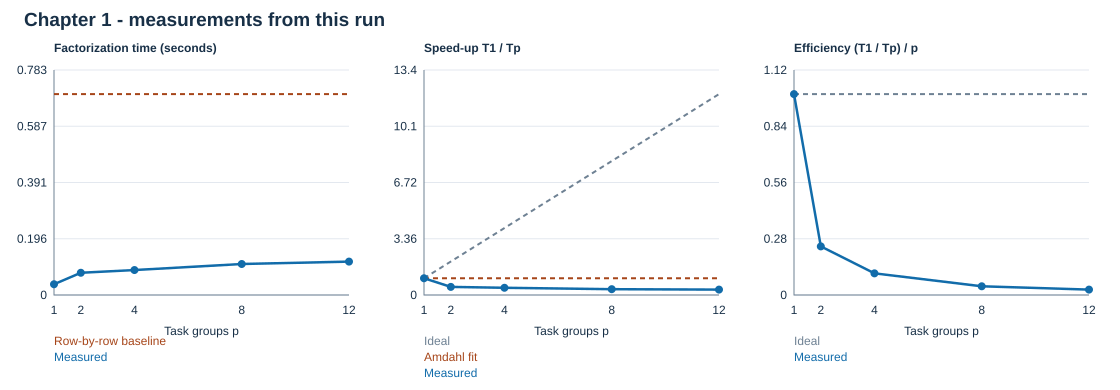

In [284]:
# TODO · Task 1.2
ps = unique(vcat([2^k for k in 0:floor(Int, log2(nthreads()))], nthreads()))
times = Dict{Int,Float64}()
for p in ps
    times[p] = bench(B -> cholesky_threads!(B; ntasks = p), A)
end

speedups = Dict(p => times[1] / times[p] for p in ps)
efficiencies = Dict(p => speedups[p] / p for p in ps)
t1_naive_time = bench(cholesky_naive!, A)

# Constrained least squares in speed-up space; grid resolution = 0.0001.
# The fitted f is empirical: Amdahl's model omits scheduling/memory overhead.
f, t1_fit_rmse = if length(ps) > 1
    candidates = range(0.0, 1.0; length = 10001)
    losses = [sum((speedups[p] - 1 / (ff + (1 - ff) / p))^2 for p in ps)
              for ff in candidates]
    best_index = argmin(losses)
    candidates[best_index], sqrt(losses[best_index] / length(ps))
else
    @warn "Use a Julia kernel with at least 2 threads to measure parallel scaling and fit Amdahl's law."
    NaN, NaN
end

t1_rows = [(tasks = p, time_s = times[p], speedup = speedups[p],
            efficiency = efficiencies[p]) for p in ps]
show_table(t1_rows)
@printf("Row-by-row baseline: %.6f s; sequential right-looking: %.6f s\n",
        t1_naive_time, times[1])
@printf("Amdahl f = %.4f; speed-up fit RMSE = %.4f\n", f, t1_fit_rmse)

record!("T1_times", times)
record!("T1_speedup_max", maximum(values(speedups)))
record!("T1_serial_fraction", f)
record!("T1_speedups", speedups)
record!("T1_efficiencies", efficiencies)
record!("T1_naive_time", t1_naive_time)
record!("T1_fit_rmse", t1_fit_rmse)
record!("T1_N", size(A, 1))

# A dependency-free SVG plot also works when optional Plots.jl is absent.
struct PersonAPlot
    svg::String
end
Base.show(io::IO, ::MIME"image/svg+xml", p::PersonAPlot) = print(io, p.svg)
Base.show(io::IO, ::PersonAPlot) = print(io, "Chapter 1: time, speed-up and efficiency plots")

function person_a_scaling_svg(ps, times, speedups, efficiencies, f, naive_time)
    io = IOBuffer()
    print(io, "<svg xmlns='http://www.w3.org/2000/svg' width='1120' height='390' viewBox='0 0 1120 390'>")
    print(io, "<rect width='1120' height='390' fill='white'/><g font-family='Arial,sans-serif' font-size='12' fill='#183047'>")
    print(io, "<text x='24' y='26' font-size='19' font-weight='bold'>Chapter 1 - measurements from this run</text>")
    xmax = max(maximum(ps), 2)
    panels = [
        ("Factorization time (seconds)", [times[p] for p in ps],
         [(fill(naive_time, length(ps)), "#a64519", "Row-by-row baseline")]),
        ("Speed-up T1 / Tp", [speedups[p] for p in ps],
         isfinite(f) ? [(Float64.(ps), "#6e8193", "Ideal"),
                        ([1 / (f + (1 - f) / p) for p in ps], "#a64519", "Amdahl fit")] :
                       [(Float64.(ps), "#6e8193", "Ideal")]),
        ("Efficiency (T1 / Tp) / p", [efficiencies[p] for p in ps],
         [(ones(length(ps)), "#6e8193", "Ideal")]),
    ]
    for (panel, (title, ys, references)) in enumerate(panels)
        left = 54 + (panel - 1) * 370
        top, w, h = 70, 295, 225
        ymax = 1.12 * max(maximum(ys), maximum(maximum(r[1]) for r in references), eps())
        x(p) = left + (p - 1) / (xmax - 1) * w
        y(v) = top + h - v / ymax * h
        print(io, "<text x='$left' y='52' font-weight='bold'>$title</text>")
        for q in 0:4
            value = ymax * q / 4
            yy = y(value)
            label = @sprintf("%.3g", value)
            print(io, "<path d='M $left $yy h $w' stroke='#e3e8ef'/><text x='$(left - 7)' y='$(yy + 4)' text-anchor='end'>$label</text>")
        end
        print(io, "<path d='M $left $top v $h h $w' fill='none' stroke='#6e8193'/>")
        for p in ps
            print(io, "<text x='$(x(p))' y='$(top + h + 19)' text-anchor='middle'>$p</text>")
        end
        print(io, "<text x='$(left + w / 2)' y='$(top + h + 40)' text-anchor='middle'>Task groups p</text>")
        for (idx, (ref_ys, color, label)) in enumerate(references)
            points = join(["$(x(p)),$(y(v))" for (p, v) in zip(ps, ref_ys)], " ")
            print(io, "<polyline points='$points' fill='none' stroke='$color' stroke-width='2' stroke-dasharray='5 4'/>")
            print(io, "<text x='$left' y='$(345 + 16 * (idx - 1))' fill='$color'>$label</text>")
        end
        points = join(["$(x(p)),$(y(v))" for (p, v) in zip(ps, ys)], " ")
        print(io, "<polyline points='$points' fill='none' stroke='#126caa' stroke-width='2.5'/>")
        for (p, v) in zip(ps, ys)
            print(io, "<circle cx='$(x(p))' cy='$(y(v))' r='4' fill='#126caa'/>")
        end
        print(io, "<text x='$left' y='$(345 + 16 * length(references))' fill='#126caa'>Measured</text>")
    end
    print(io, "</g></svg>")
    return String(take!(io))
end

t1_plot_svg = person_a_scaling_svg(ps, times, speedups, efficiencies, f, t1_naive_time)
display(PersonAPlot(t1_plot_svg))

In [285]:
# TODO · Task 1.3
t1_best_p = ps[argmax([speedups[p] for p in ps])]

ANSWERS["T1_scaling"] =
                if length(ps) > 1
                    @sprintf("""
                                At N = %d, the best speed-up was %.3fx at p = %d task groups; at p = %d, speed-up was %.3fx and efficiency was %.3f. 
                                The constrained Amdahl fit gave an effective serial fraction f = %.4f with speed-up RMSE %.4f. 
                                Sequential column factorization/scaling, a barrier after each trailing update, task scheduling, 
                                and memory bandwidth limit scaling and can even cause a slowdown, so this fitted fraction is not a direct measurement of purely serial work.
                            """,
                                size(A, 1), speedups[t1_best_p], t1_best_p, last(ps),
                                speedups[last(ps)], efficiencies[last(ps)], f, t1_fit_rmse
                    )
                else
                    """
                        Only one Julia thread was available, so this run cannot measure parallel scaling or identify an Amdahl serial fraction.
                        A kernel with at least two threads is needed for the final experiment. In general, sequential column work, barriers,
                        task scheduling, and memory bandwidth limit scaling.
                    """
                end

ANSWERS["T1_dependencies"] = """
                                In the row-by-row baseline, each row uses previously computed entries of L, so arbitrary rows cannot be factored independently. 
                                After column j is factored and scaled in the right-looking form, each task updates separate trailing columns using the completed column j, 
                                avoiding conflicting writes. The @sync barrier ensures all these updates finish before the next pivot is read.
                            """

println("T1_scaling: ", ANSWERS["T1_scaling"])
println()
println("T1_dependencies: ", ANSWERS["T1_dependencies"])


T1_scaling:     At N = 1024, the best speed-up was 1.000x at p = 1 task groups; at p = 12, speed-up was 0.322x and efficiency was 0.027. 
    The constrained Amdahl fit gave an effective serial fraction f = 1.0000 with speed-up RMSE 0.5433. 
    Sequential column factorization/scaling, a barrier after each trailing update, task scheduling, 
    and memory bandwidth limit scaling and can even cause a slowdown, so this fitted fraction is not a direct measurement of purely serial work.


T1_dependencies:     In the row-by-row baseline, each row uses previously computed entries of L, so arbitrary rows cannot be factored independently. 
    After column j is factored and scaled in the right-looking form, each task updates separate trailing columns using the completed column j, 
    avoiding conflicting writes. The @sync barrier ensures all these updates finish before the next pivot is read.



In [286]:
# CHECK · Chapter 1
check("T1 correct, sequential (ntasks = 1)", () -> passes(B -> cholesky_threads!(B; ntasks = 1)); points = 2)
check("T1 correct, parallel (ntasks = nthreads())", () -> passes(B -> cholesky_threads!(B; ntasks = nthreads())); points = 2)
check("T1 correct with more tasks than columns (n = 31, ntasks = 64)", () -> passes(B -> cholesky_threads!(B; ntasks = 64); n = 31); points = 1)
check("T1 timings and Amdahl fit recorded", () -> haskey(RESULTS, "T1_times") && length(RESULTS["T1_times"]) >= min(2, length(ps)) &&
                                                  haskey(RESULTS, "T1_serial_fraction"); points = 1)

✅ T1 correct, sequential (ntasks = 1)  [2 pt]
✅ T1 correct, parallel (ntasks = nthreads())  [2 pt]
✅ T1 correct with more tasks than columns (n = 31, ntasks = 64)  [1 pt]
✅ T1 timings and Amdahl fit recorded  [1 pt]


true

> *Plot twist:* for every one of the $n$ columns you spawn tasks and wait at a barrier, often for a few microseconds of work each. The tasks are too **fine-grained**. What if each task did a whole block of work instead?

---
# Chapter 2 · Coarse- vs fine-grained tasks — *The right size of a job* (14 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 2</b><br>Group the matrix into <b>tiles</b> of size nb × nb and make one task per <i>tile operation</i>. The tile size nb is now the knob that sets granularity. Small nb gives many tiny tasks, with high scheduling overhead and little cache reuse. Large nb gives a few big tasks, with idle threads and load imbalance. Somewhere in between is the sweet spot, and you have to find it.</div>

### Task 2.1 · Implement the tiled algorithm
With $p = \lceil n/nb \rceil$ tile rows, for $k = 1{:}p$:

| Step | Operation | Tiles | Parallel? |
|---|---|---|---|
| POTRF | $A_{kk} = L_{kk}L_{kk}^\top$ | diagonal tile $k$ | sequential |
| TRSM | $A_{ik} \leftarrow A_{ik}L_{kk}^{-\top}$ | $i = k{+}1{:}p$ | one task per tile |
| SYRK / GEMM | $A_{ij} \leftarrow A_{ij} - A_{ik}A_{jk}^\top$ | $k < j \le i \le p$ | one task per tile |

* Write the three tile kernels with **plain loops**. No BLAS here; that comes in Chapter 5.
* Use `view(A, tile(i, nb, n), tile(k, nb, n))` and never copies. The last tile may be smaller than nb, and nb may be larger than n.
* With `parallel = true`, wrap each phase in `@sync` and `Threads.@spawn` one task per tile. With `parallel = false`, run the same loops without tasks.

In [287]:
# TODO · Task 2.1
tile(i::Int, nb::Int, n::Int) = ((i - 1) * nb + 1):min(i * nb, n)    # PROVIDED: rows/cols of tile i

"POTRF: factor a diagonal tile in place (lower triangle). Hint: any of your loop factorizations works on a view."
function tile_potrf!(Akk::AbstractMatrix)
    n = size(Akk, 1)

    for j in 1:n
        d = Akk[j, j]

        d > zero(eltype(Akk)) || throw(PosDefException(j))
        Akk[j, j] = sqrt(d)

        for i in j+1:n
            Akk[i, j] /= Akk[j, j]
        end

        for c in j+1:n
            for r in c:n
                Akk[r, c] -= Akk[r, j] * Akk[c, j]
            end
        end
    end
    
    return Akk
end

"TRSM: overwrite Aik with Aik · Lkk⁻ᵀ, i.e. solve X · Lkkᵀ = Aik row by row (forward substitution with Lkk)."
function tile_trsm!(Aik::AbstractMatrix, Lkk::AbstractMatrix)
    n = size(Aik, 1)
    m = size(Aik, 2)

    for i in 1:n
        for j in 1:m
            s = Aik[i, j]

            for t in 1:j-1
                s -= Aik[i, t] * Lkk[j, t]
            end
            
            Aik[i, j] = s / Lkk[j, j]
        end
    end

    return Aik
end

"SYRK/GEMM: Aij ← Aij − Aik · Ajkᵀ (on a diagonal tile only the lower triangle needs updating)."
function tile_update!(Aij::AbstractMatrix, Aik::AbstractMatrix, Ajk::AbstractMatrix)
    r = size(Aij, 1)
    c = size(Aij, 2)
    t = size(Aik, 2)

    for i in 1:r
        for j in 1:c
            s = zero(eltype(Aij))

            for k in 1:t
                s += Aik[i, k] * Ajk[j, k]
            end

            Aij[i, j] -= s
        end
    end

    return Aij
end

"""
    cholesky_tiled!(A, nb; parallel = true) -> A
Tiled right-looking Cholesky with one task per tile operation (see the table above).
"""
function cholesky_tiled!(A::AbstractMatrix{T}, nb::Int; parallel::Bool = true) where {T<:AbstractFloat}
    n = size(A, 1); p = cld(n, nb)
    for k in 1:p
        # POTRF → @sync TRSM tasks → @sync update tasks
        Akk = view(A, tile(k, nb, n), tile(k, nb, n))
        tile_potrf!(Akk)

        if parallel
            @sync begin
                for i in k+1:p
                    let Aik = view(A, tile(i, nb, n), tile(k, nb, n))
                        Lkk = Akk
                        Threads.@spawn tile_trsm!(Aik, Lkk)
                    end
                end
            end

            @sync begin
                for j in k+1:p
                    for i in j:p
                        let Aij = view(A, tile(i, nb, n), tile(j, nb, n)),
                            Aik = view(A, tile(i, nb, n), tile(k, nb, n)),
                            Ajk = view(A, tile(j, nb, n), tile(k, nb, n))
                            
                            Threads.@spawn tile_update!(Aij, Aik, Ajk)
                        end
                    end
                end
            end
        else 
            for i in k+1:p
                Aik = view(A, tile(i, nb, n), tile(k, nb, n))
                tile_trsm!(Aik, Akk)
            end

            for j in k+1:p
                for i in j:p
                    Aij = view(A, tile(i, nb, n), tile(j, nb, n))
                    Aik = view(A, tile(i, nb, n), tile(k, nb, n))
                    Ajk = view(A, tile(j, nb, n), tile(k, nb, n))

                    tile_update!(Aij, Aik, Ajk)
                end
            end
        end
    end

    return A
end

cholesky_tiled! (generic function with 1 method)

### Task 2.2 · Experiment: granularity sweep
1. Time `cholesky_tiled!(A, nb)` for nb in `NBS`, plus the sequential version (`parallel = false`) at your best nb.
2. For each nb, compute the **number of tasks** spawned and the **average flops per task**. Compare with Chapter 1, which has one barrier per column and $\approx n \cdot$`ntasks` spawns.
3. Plot time (or GFlop/s) against nb and explain the U-shape. Set `BEST_NB`; it is reused later.
4. `record!("T2_nb_times", Dict(nb => t))`, `record!("T2_best_nb", BEST_NB)`, `record!("T2_tasks_per_nb", Dict(nb => ntasks))`.

In [288]:
# Parallel timing sweep

NBS = filter(nb -> nb <= N, [8, 16, 32, 64, 128, 256, 512])
nb_times = Dict{Int,Float64}()

for nb in NBS
    nb_times[nb] = bench(
        B -> cholesky_tiled!(B, nb; parallel = true),
        A
    )

    @printf("nb = %3d | time = %.3f ms\n", nb, 1000 * nb_times[nb])
end

nb =   8 | time = 250.519 ms
nb =  16 | time = 87.837 ms
nb =  32 | time = 68.352 ms
nb =  64 | time = 65.454 ms
nb = 128 | time = 73.911 ms
nb = 256 | time = 206.406 ms
nb = 512 | time = 780.368 ms


#### Task counts and work per task

In [289]:
tasks_per_nb = Dict{Int,Int}()
avg_flops_per_task = Dict{Int,Float64}()

for nb in NBS
    p = cld(N, nb)
    count_tasks = 0
    total_flops = 0.0

    for k in 1:p
        q = length(tile(k, nb, N))

        # TRSM tasks
        for i in k+1:p
            ni = length(tile(i, nb, N))

            count_tasks += 1
            total_flops += ni * q^2
        end

        # UPDATE tasks
        for j in k+1:p
            nj = length(tile(j, nb, N))

            for i in j:p
                ni = length(tile(i, nb, N))

                count_tasks += 1
                total_flops += ni * nj * (2*q + 1)
            end
        end
    end

    tasks_per_nb[nb] = count_tasks
    avg_flops_per_task[nb] =
        count_tasks == 0 ? NaN : total_flops / count_tasks
end

#### Select `BEST_NB` and compare sequential versus parallel

In [290]:
BEST_NB = NBS[argmin([nb_times[nb] for nb in NBS])]

t_seq = bench(
    B -> cholesky_tiled!(B, BEST_NB; parallel = false),
    A
)

t_par = nb_times[BEST_NB]
speedup = t_seq / t_par

println("Best tile size: ", BEST_NB)
@printf("Sequential: %.3f ms\n", 1000 * t_seq)
@printf("Parallel:   %.3f ms\n", 1000 * t_par)
@printf("Speed-up:   %.2f×\n", speedup)

Best tile size: 64
Sequential: 188.980 ms
Parallel:   65.454 ms
Speed-up:   2.89×


#### Display the `summary table` and `Chapter 1` comparison

In [291]:
let
    ch1_times = RESULTS["T1_times"]
    @assert RESULTS["T1_N"] == N "Rerun Chapter 1 at the current N."

    t2_best = nb_times[BEST_NB]

    println("Chapter 2: granularity sweep")
    println("N = $N | Julia threads = $(nthreads())")

    show_table([
        (
            nb = nb,
            time_ms = 1000 * nb_times[nb],
            tasks = tasks_per_nb[nb],
            flops_per_task = avg_flops_per_task[nb],
            barriers = 2 * max(cld(N, nb) - 1, 0)
        )
        for nb in NBS
    ]; w = 18)

    # Exact counts for the implemented Chapter 1 algorithm.
    # ntasks=1 runs sequentially without spawning tasks.
    ch1_tasks(p) = p == 1 ? 0 :
        sum(min(p, N - j) for j in 1:N)

    # Arithmetic performed by the spawned trailing-update tasks.
    ch1_update_flops = Float64(N) * (N - 1) * (N + 1) / 3
    groups = sort(collect(keys(ch1_times)))

    println("\nChapter 1: measured timings and exact task counts")

    show_table([
        (
            ntasks = p,
            time_ms = 1000 * ch1_times[p],
            tasks = ch1_tasks(p),
            flops_per_task = p == 1 ? NaN :
                ch1_update_flops / ch1_tasks(p),
            barriers = p == 1 ? 0 : max(N - 1, 0),
            T1_over_T2 = ch1_times[p] / t2_best
        )
        for p in groups
    ]; w = 18)

    println("\nbarriers = synchronization phases containing tasks.")
    println("NaN FLOPs/task = no spawned tasks.")
    println("T1_over_T2 = Chapter 1 time / best Chapter 2 parallel=true time.")
    println("A ratio > 1 favors Chapter 2; a ratio < 1 favors Chapter 1.")

    best_p = groups[argmin([ch1_times[p] for p in groups])]

    println("\nComparison:")
    @printf("Chapter 1 best: ntasks=%d, %.4f ms\n",
            best_p, 1000 * ch1_times[best_p])
    @printf("Chapter 2 best parallel=true: nb=%d, %.4f ms\n",
            BEST_NB, 1000 * t2_best)
    @printf("Chapter 2 parallel=false at the same nb: %.4f ms\n",
            1000 * t_seq)

    @printf("\nChapter 1 best / Chapter 2 best parallel=true: %.3fx\n",
            ch1_times[best_p] / t2_best)
    @printf("Chapter 1 sequential / Chapter 2 sequential: %.3fx\n",
            ch1_times[1] / t_seq)
    @printf("Chapter 2 sequential / parallel=true: %.3fx\n",
            t_seq / t2_best)

    parallel_groups = filter(p -> p > 1, groups)
    if !isempty(parallel_groups)
        best_parallel_p = parallel_groups[
            argmin([ch1_times[p] for p in parallel_groups])
        ]

        @printf("\nChapter 1 best with spawned tasks: ntasks=%d, %.4f ms\n",
                best_parallel_p, 1000 * ch1_times[best_parallel_p])
        @printf("Its time / Chapter 2 best parallel=true time: %.3fx\n",
                ch1_times[best_parallel_p] / t2_best)
    end

    if tasks_per_nb[BEST_NB] == 0
        println("\nAt BEST_NB, Chapter 2 executes one sequential POTRF tile.")
        println("It spawns no tasks, even with parallel=true.")
        println("Beating Chapter 1's threaded runs therefore does not")
        println("demonstrate a benefit from parallel execution.")
    end

    if REPS == 1
        println("\nThese timings use one repetition (QUICK=true).")
        println("Repeat measurements before drawing firm performance conclusions.")
    end
end

Chapter 2: granularity sweep
N = 1024 | Julia threads = 12
nb                time_ms           tasks             flops_per_task    barriers          
8                 250.5             357632            1075              254               
16                87.84             45696             8256              126               
32                68.35             5952              6.374e+04         62                
64                65.45             800               4.884e+05         30                
128               73.91             112               3.682e+06         14                
256               206.4             16                2.73e+07          6                 
512               780.4             2                 2.015e+08         2                 

Chapter 1: measured timings and exact task counts
ntasks            time_ms           tasks             flops_per_task    barriers          T1_over_T2        
1                 37.43             0                

#### Plotting the results

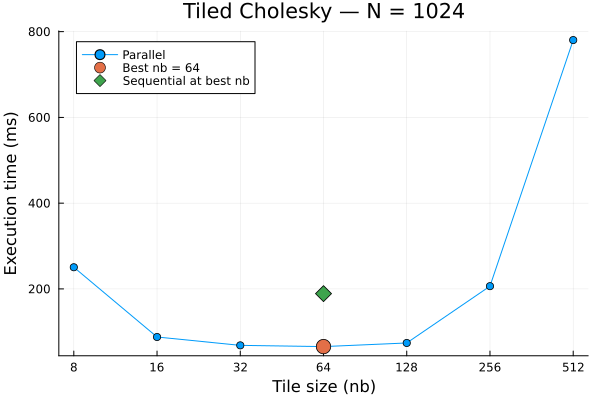

In [292]:
if HAS_PLOTS
    times_ms = [1000 * nb_times[nb] for nb in NBS]

    plt_t2 = plot(
        NBS, times_ms;
        marker = :circle,
        xlabel = "Tile size (nb)",
        ylabel = "Execution time (ms)",
        title = "Tiled Cholesky — N = $N",
        label = "Parallel",
        xscale = :log2,
        xticks = (NBS, string.(NBS))
    )

    scatter!(
        plt_t2,
        [BEST_NB], [1000 * t_par];
        label = "Best nb = $BEST_NB",
        markersize = 8
    )

    scatter!(
        plt_t2,
        [BEST_NB], [1000 * t_seq];
        label = "Sequential at best nb",
        markershape = :diamond,
        markersize = 8
    )

    display(plt_t2)
else
    println("Plots.jl is unavailable; timings are shown in the table above.")
end

In [293]:
# TODO · Task 2.2 — interpretation generated from the measured sweep
t2_shape = BEST_NB != first(NBS) && BEST_NB != last(NBS) ?
    "The measured curve has an interior minimum: small tiles incur scheduling overhead, while large tiles reduce concurrency and increase the cost of the row-oriented tile kernels." :
    "The minimum is at an endpoint of the tested range; these measurements do not establish an interior U-shaped optimum."
t2_parallel = tasks_per_nb[BEST_NB] == 0 ?
    "This configuration spawns no tasks, so it does not demonstrate parallel speed-up." :
    @sprintf("At the same tile size, sequential execution takes %.3f ms: parallel speed-up is %.3fx and efficiency relative to %d Julia threads is %.1f%%.",
             1000t_seq, t_seq / t_par, nthreads(), 100t_seq / t_par / nthreads())
display(MIME"text/markdown"(), @sprintf("""
**Interpretation of this run (N = %d).** The fastest tested tile size is **nb = %d** at **%.3f ms**, with **%d spawned tasks**.
%s %s
The best Chapter 1 configuration takes %.3f ms; its time divided by the best tiled time is %.3f (values above 1 favor tiling).
The selected tile size is an empirical minimum, not a universal optimum; close timings require repeated runs to distinguish reliably.
""", N, BEST_NB, 1000t_par, tasks_per_nb[BEST_NB], t2_shape, t2_parallel,
     minimum(values(RESULTS["T1_times"])) * 1000, minimum(values(RESULTS["T1_times"])) / t_par))

**Interpretation of this run (N = 1024).** The fastest tested tile size is **nb = 64** at **65.454 ms**, with **800 spawned tasks**.
The measured curve has an interior minimum: small tiles incur scheduling overhead, while large tiles reduce concurrency and increase the cost of the row-oriented tile kernels. At the same tile size, sequential execution takes 188.980 ms: parallel speed-up is 2.887x and efficiency relative to 12 Julia threads is 24.1%.
The best Chapter 1 configuration takes 37.430 ms; its time divided by the best tiled time is 0.572 (values above 1 favor tiling).
The selected tile size is an empirical minimum, not a universal optimum; close timings require repeated runs to distinguish reliably.


In [294]:
#Required exports

record!("T2_nb_times", nb_times)
record!("T2_best_nb", BEST_NB)
record!("T2_tasks_per_nb", tasks_per_nb);

In [295]:
# TODO · Task 2.3 — answers
ANSWERS["T2_granularity"] = @sprintf("""
At N = %d, nb = %d is the fastest tested loop tile size (%.3f ms; %d spawned tasks).
%s %s
The tile choice balances scheduling overhead, available parallelism and locality; it must be retuned for another size or kernel.
""", N, BEST_NB, 1000t_par, tasks_per_nb[BEST_NB], t2_shape, t2_parallel)
ANSWERS["T2_barriers"] = """
Each panel has a barrier after its TRSM tasks and another after its trailing updates.
A dependency scheduler could start an update as soon as both input tiles and the preceding update of its output tile are ready.
The next POTRF could start once its diagonal tile is fully updated, without waiting for unrelated trailing tiles.
"""
println("T2_granularity: ", ANSWERS["T2_granularity"])
println("T2_barriers: ", ANSWERS["T2_barriers"])

T2_granularity: At N = 1024, nb = 64 is the fastest tested loop tile size (65.454 ms; 800 spawned tasks).
The measured curve has an interior minimum: small tiles incur scheduling overhead, while large tiles reduce concurrency and increase the cost of the row-oriented tile kernels. At the same tile size, sequential execution takes 188.980 ms: parallel speed-up is 2.887x and efficiency relative to 12 Julia threads is 24.1%.
The tile choice balances scheduling overhead, available parallelism and locality; it must be retuned for another size or kernel.

T2_barriers: Each panel has a barrier after its TRSM tasks and another after its trailing updates.
A dependency scheduler could start an update as soon as both input tiles and the preceding update of its output tile are ready.
The next POTRF could start once its diagonal tile is fully updated, without waiting for unrelated trailing tiles.



In [296]:
# CHECK · Chapter 2
check("T2 tile_trsm! solves X·Lᵀ = B", () -> begin
    L = Matrix(LowerTriangular(rand(Xoshiro(1), 8, 8) + 8I)); B = rand(Xoshiro(2), 5, 8); X = copy(B)
    tile_trsm!(X, L); norm(X * L' - B) <= 1e-10 * norm(B)
end; points = 1)
check("T2 tile_update! lower triangle (informative)", () -> begin
    C = rand(Xoshiro(3), 6, 6); P = rand(Xoshiro(4), 6, 4); Q = rand(Xoshiro(5), 6, 4); C2 = copy(C)
    tile_update!(C2, P, Q); norm(tril(C2) - tril(C - P * Q')) <= 1e-12 * norm(C)
end)
check("T2 tiled, parallel, correct (n = 203, nb = 32)", () -> passes(B -> cholesky_tiled!(B, 32)); points = 2)
check("T2 tiled, sequential, correct", () -> passes(B -> cholesky_tiled!(B, 32; parallel = false)); points = 1)
check("T2 edge cases: ragged tiles (nb = 17) and nb > n (nb = 512)",
      () -> passes(B -> cholesky_tiled!(B, 17)) && passes(B -> cholesky_tiled!(B, 512)); points = 1)
check("T2 granularity sweep recorded", () -> haskey(RESULTS, "T2_nb_times") && length(RESULTS["T2_nb_times"]) >= 3 &&
                                             haskey(RESULTS, "T2_best_nb"); points = 1)

✅ T2 tile_trsm! solves X·Lᵀ = B  [1 pt]
✅ T2 tile_update! lower triangle (informative)
✅ T2 tiled, parallel, correct (n = 203, nb = 32)  [2 pt]
✅ T2 tiled, sequential, correct  [1 pt]
✅ T2 edge cases: ragged tiles (nb = 17) and nb > n (nb = 512)  [1 pt]
✅ T2 granularity sweep recorded  [1 pt]


true

> *Plot twist:* the director asks, "Do we really need 16 digits? The sensor data has 3." Half the bits means half the bytes to move and twice the SIMD lanes. Is that free speed?

---
# Chapter 3 · Precision — *Half the bits, twice the speed?* (14 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 3</b><br>Your kernels are generic in the element type <code>T</code>, so Float32 costs nothing to try. Float32 has ε ≈ 6·10⁻⁸ instead of 1·10⁻¹⁶, so you lose about eight digits. <b>Mixed-precision iterative refinement</b> keeps the speed and recovers the digits: do the O(n³) factorization in Float32, then correct the solution with cheap O(n²) residuals computed in Float64.</div>

### Task 3.1 · Same code, different precision
Time your best factorization in **Float64** and **Float32** on `generate_spd(N; T = …)`. For each, report time, GFlop/s, backward error and forward error.
*(Optional)* Try `Float16` at a small N. Why is it *slower* on most CPUs?
`record!("T3_times", Dict("Float64" => …, "Float32" => …))` and `record!("T3_backward_errors", Dict(…))`.

In [297]:
# TODO · Task 3.1
# A64 = generate_spd(N; T = Float64); A32 = generate_spd(N; T = Float32)
# t64 = bench(B -> cholesky_tiled!(B, BEST_NB), A64); t32 = …
# … backward / forward errors (use b and x_true converted to each precision) …
# record!("T3_times", Dict("Float64" => t64, "Float32" => t32)); record!("T3_backward_errors", Dict(…))


# Compare the Chapter 2 tiled kernel at its selected tile size in both precisions.
# This is the best tiled configuration, not necessarily the fastest of all loop algorithms.
# The ! suffix convention indicates that the function modifies its argument.
# we have cholesky_tiled!(B, BEST_NB) factorization function that uses the best tile size found in Task 2.2.
function best_factor!(B)
    return cholesky_tiled!(B, BEST_NB)
end

# Generate matrices.
A64 = generate_spd(N; T = Float64) # generate a symmetric positive definite matrix of size N with Float64 precision
A32 = generate_spd(N; T = Float32) # generate a symmetric positive definite matrix of size N with Float32 precision

# Generate known solutions.
xtrue64 = generate_solution(N; T = Float64) #
xtrue32 = generate_solution(N; T = Float32)

# Calculate right-hand sides.
b64 = A64 * xtrue64
b32 = A32 * xtrue32

# Measure factorization times.
# bench(best_factor!, A) runs the best_factor! function on a copy of A and returns the time taken.
t64 = bench(best_factor!, A64)
t32 = bench(best_factor!, A32)

# Copy matrices to preserve the originals.
F64 = copy(A64)
F32 = copy(A32)

# Factor the copied matrices.
best_factor!(F64)
best_factor!(F32)

# Copy right-hand sides.
x64 = copy(b64)
x32 = copy(b32)

# Solve using the Cholesky factors.
chol_solve!(F64, x64)
chol_solve!(F32, x32)

# Calculate backward errors.
η64 = backward_error(A64, x64, b64)
η32 = backward_error(A32, x32, b32)

# Calculate forward errors.
fe64 = forward_error(x64, xtrue64)
fe32 = forward_error(x32, xtrue32)

# Calculate GFlop/s.
#GFlop/s is calculated as the number of floating-point operations (flops) divided by the time taken (t) in seconds, converted to gigaflops (1e9 flops).
flops = chol_flops(N)
gf64 = gflops(flops, t64)
gf32 = gflops(flops, t32)

# Calculate Float32 speed-up.
speedup = t64 / t32

# Display Float64 results.
println("Float64:")
println("Time (s): ", t64)
println("GFlop/s: ", gf64)
println("Backward error: ", η64)
println("Forward error: ", fe64)

# Display Float32 results.
println("\nFloat32:")
println("Time (s): ", t32)
println("GFlop/s: ", gf32)
println("Backward error: ", η32)
println("Forward error: ", fe32)

println("\nFloat32 speed-up: ", speedup)

# Store times in a dictionary.
times = Dict("Float64" => t64, "Float32" => t32)
record!("T3_times", times)

# Store backward errors in a dictionary.
errors = Dict("Float64" => η64, "Float32" => η32)

record!("T3_backward_errors", errors)

Float64:
Time (s): 0.0614619
GFlop/s: 5.831879587191414
Backward error: 7.705283028896823e-16
Forward error: 4.1139386277482216e-13

Float32:
Time (s): 0.0637941
GFlop/s: 5.618676335272384
Backward error: 6.913772134810278e-7
Forward error: 0.0002629106547525037

Float32 speed-up: 0.9634417602881771


Dict{String, Float64} with 2 entries:
  "Float32" => 6.91377e-7
  "Float64" => 7.70528e-16

### Task 3.2 · Mixed-precision iterative refinement
```
F = factor!(Float32.(A))                          # O(n³) in fast low precision
x = Float64.(chol_solve!(F, Float32.(b)))
repeat:  r = b − A·x   (Float64)                  # O(n²)
         d = chol_solve!(F, Float32.(r))          # O(n²), reuses the factor
         x = x + d
until backward_error(A, x, b) ≤ tol  or  maxiter steps
```
Return `(x, iters, history)`, where `history` holds the backward error after each step. Set the default `factor!` to your fastest correct factorization.

In [298]:
# TODO · Task 3.2
"""
    solve_mixed_ir(A, b; maxiter = 10, tol = 4eps(Float64), factor! = best_factor!) -> (x, iters, history)
Float32 factorization + Float64 iterative refinement. x is a Vector{Float64}.
"""
function solve_mixed_ir(A::AbstractMatrix{Float64},b::AbstractVector{Float64};
    maxiter::Int = 10,tol::Real = 4eps(Float64),factor! = best_factor!)
    # maxiter: maximum number of iterations for the iterative refinement
    # tol: tolerance for the backward error to stop the refinement

    # Convert A to Float32 and factorize it once.
    F32 = Float32.(A)
    factor!(F32)

    # Compute an initial solution in Float32.
    x32 = Float32.(b)
    chol_solve!(F32, x32)

    # Store the solution in Float64.
    x = Float64.(x32)

    # Save the initial backward error.
    error_value = backward_error(A, x, b)
    history = [error_value]
    iters = 0

    while error_value > tol && iters < maxiter
        # Calculate the residual in Float64.
        Ax = A * x
        r = b - Ax

        # Solve for a correction using the Float32 factors.
        d32 = Float32.(r)
        chol_solve!(F32, d32)

        # Convert the correction to Float64 and update x.
        d64 = Float64.(d32)
        x = x + d64

        # Save the new error.
        iters = iters + 1
        error_value = backward_error(A, x, b)
        push!(history, error_value)
    end

    return x, iters, history
end

solve_mixed_ir (generic function with 1 method)

### Task 3.3 · Experiment
Plot the backward-error history against the iteration number, with $\varepsilon_{64}$ and $\varepsilon_{32}$ as horizontal lines. Compare the **total** time of IR with a pure Float64 factorization plus solve.
`record!("T3_ir_iters", iters)`, `record!("T3_ir_time", …)`, `record!("T3_ir_backward_error", …)`.

Mixed-precision total time (s): 0.2093757
Float64 total time (s): 0.0813812
Mixed-precision speed-up: 0.3886850288739333
Correction steps: 10
Final backward error: 7.705283028896693e-16
Tolerance reached: true


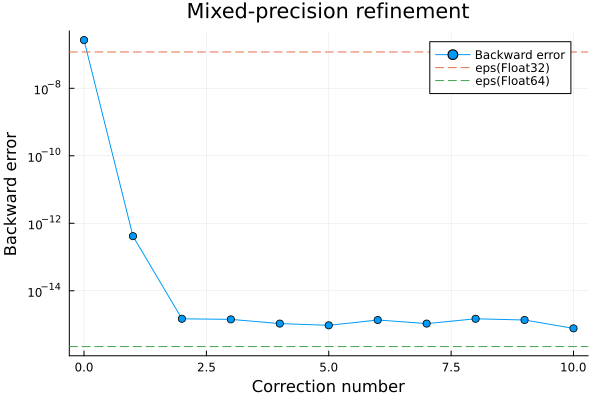

In [299]:
# TODO · Task 3.3
# x_ir, it_ir, hist = solve_mixed_ir(A, b; factor! = B -> cholesky_tiled!(B, BEST_NB))
# t_ir = @elapsed solve_mixed_ir(A, b; factor! = …)
# record!("T3_ir_iters", it_ir); record!("T3_ir_time", t_ir); record!("T3_ir_backward_error", backward_error(A, x_ir, b))


# Complete mixed-precision solve.
function run_mixed()
    return solve_mixed_ir(A64, b64; factor! = best_factor!)
end

# Complete Float64 factorization and solve.
function run_float64()
    F = copy(A64)
    best_factor!(F)

    x = copy(b64)
    chol_solve!(F, x)

    return x
end

# Warm up both functions before measuring time.
run_mixed()
run_float64()

# Repeat timings and keep the smallest time.
t_ir = Inf
t_float64 = Inf

for rep in 1:REPS
    elapsed_ir = @elapsed run_mixed()
    elapsed_float64 = @elapsed run_float64()

    global t_ir = min(t_ir, elapsed_ir)
    global t_float64 = min(t_float64, elapsed_float64)
end

# Obtain the mixed solution and its error history.
x_ir, iters, history = run_mixed()

# Calculate final accuracy and speed-up.
final_error = backward_error(A64, x_ir, b64)
speedup_ir = t_float64 / t_ir

println("Mixed-precision total time (s): ", t_ir)
println("Float64 total time (s): ", t_float64)
println("Mixed-precision speed-up: ", speedup_ir)
println("Correction steps: ", iters)
println("Final backward error: ", final_error)
println("Tolerance reached: ", final_error <= 4eps(Float64))

# Save the required results.
record!("T3_ir_iters", iters)
record!("T3_ir_time", t_ir)
record!("T3_ir_backward_error", final_error)

# Save the Float64 comparison time.
record!("T3_float64_total_time", t_float64)

# Plot error against correction number.
if HAS_PLOTS
    iterations = 0:iters

    # Replace zero only for plotting on a logarithmic axis.
    plot_errors = copy(history)
    for i in eachindex(plot_errors)
        if plot_errors[i] == 0
            plot_errors[i] = floatmin(Float64)
        end
    end

    p = plot(
        iterations, plot_errors;
        yscale = :log10,
        marker = :circle,
        xlabel = "Correction number",
        ylabel = "Backward error",
        title = "Mixed-precision refinement",
        label = "Backward error"
    )

    hline!(
        p, [Float64(eps(Float32))];
        label = "eps(Float32)",
        linestyle = :dash
    )

    hline!(
        p, [eps(Float64)];
        label = "eps(Float64)",
        linestyle = :dash
    )

    display(p)
else
    println("Plots.jl is needed for the required graph.")
end

**Reading the refinement plot.** The dashed Float64 reference is `eps(Float64)`, whereas the stopping tolerance is `4eps(Float64)`: a successful final point can therefore lie above that dashed line. Near roundoff, small fluctuations in the backward error are possible; reaching the displayed tolerance does not require a strictly decreasing history.

In [300]:
# TODO · Task 3 — interpretations from this run
ANSWERS["T3_tradeoff"] = @sprintf("""
For the tiled kernel at N = %d and nb = %d, Float64 takes %.6f s and Float32 %.6f s, giving a Float32 speed-up ratio of %.3fx (%s).
Backward error changes from %.3e to %.3e, a %.2f-decade increase, while forward error changes from %.3e to %.3e, a %.2f-decade increase.
These error ratios describe the generated systems, not a universal number of correct digits: the two precisions generate different random matrices, and forward error also depends on conditioning.
Reduced storage alone does not guarantee a speed-up when task overhead and kernel efficiency matter.
""", N, BEST_NB, t64, t32, t64/t32, t64 > t32 ? "Float32 is faster" : "Float32 is slower",
     η64, η32, log10(η32/η64), fe64, fe32, log10(fe32/fe64))
ANSWERS["T3_ir"] = @sprintf("""
Iterative refinement computes Float64 residuals and solution updates while reusing the Float32 factors for correction solves.
At N = %d, %d corrections give backward error %.3e against tolerance %.3e; the tolerance is %s.
The complete mixed solve takes %.6f s versus %.6f s for the same tiled kernel in Float64 (Float64/mixed time ratio %.3fx), including conversions, copies, residual/error calculations and triangular solves.
Convergence is favored when kappa(A)*eps(Float32) is well below 1; poorly conditioned systems can stagnate, and success here establishes backward accuracy rather than identical forward accuracy or a guaranteed speed benefit at N = 4096.
""", N, iters, final_error, 4eps(Float64), final_error <= 4eps(Float64) ? "met" : "not met",
     t_ir, t_float64, t_float64/t_ir)
println("T3_tradeoff: ", ANSWERS["T3_tradeoff"])
println("T3_ir: ", ANSWERS["T3_ir"])

T3_tradeoff: For the tiled kernel at N = 1024 and nb = 64, Float64 takes 0.061462 s and Float32 0.063794 s, giving a Float32 speed-up ratio of 0.963x (Float32 is slower).
Backward error changes from 7.705e-16 to 6.914e-07, a 8.95-decade increase, while forward error changes from 4.114e-13 to 2.629e-04, a 8.81-decade increase.
These error ratios describe the generated systems, not a universal number of correct digits: the two precisions generate different random matrices, and forward error also depends on conditioning.
Reduced storage alone does not guarantee a speed-up when task overhead and kernel efficiency matter.

T3_ir: Iterative refinement computes Float64 residuals and solution updates while reusing the Float32 factors for correction solves.
At N = 1024, 10 corrections give backward error 7.705e-16 against tolerance 8.882e-16; the tolerance is met.
The complete mixed solve takes 0.209376 s versus 0.081381 s for the same tiled kernel in Float64 (Float64/mixed time ratio 0.389x), 

> **Transition:** The precision experiment separates storage savings from measured speed and accuracy. Chapter 4 now examines how loop order and data access affect performance; no hardware-counter profiling is claimed here.

---
# Chapter 4 · Reducing data movement — *The road, not the engine* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 4</b><br>Julia stores matrices <b>column by column</b>. The baseline's inner loop <code>A[i,k]·A[j,k]</code> walks <i>along rows</i>, so every access jumps n·8 bytes and lands on a new cache line: the core spends its time waiting for memory. Reorder the loops so the innermost one runs <b>down a column</b>, remove bounds checks, let the compiler vectorize, and make sure not a single byte is allocated on the heap.</div>

### Task 4.1 · Implement `cholesky_left!(A)`: left-looking, column-oriented ("jki")
For $j = 1{:}n$:  for $k = 1{:}j{-}1$: $A_{ij} \mathrel{-}= A_{ik}A_{jk}$ for $i = j{:}n$, with the **innermost loop over $i$** (stride 1). Then $A_{jj} \leftarrow \sqrt{A_{jj}}$ and $A_{j+1:n,\,j} \mathrel{/}= A_{jj}$.
Requirements: `@inbounds` and `@simd` on the inner loop, and **zero heap allocations**. Slices like `A[j:n, k]` copy, so use loops or `view`s.

In [301]:
# TODO · Task 4.1
"Left-looking j-k-i Cholesky with contiguous inner loops and no heap allocations."
function cholesky_left!(A::AbstractMatrix{T}) where {T<:AbstractFloat}
    Base.require_one_based_indexing(A)
    n = size(A, 1)
    size(A, 2) == n || throw(DimensionMismatch("A must be square"))
    for j in 1:n
        for k in 1:j-1
            ajk = @inbounds A[j, k]
            @inbounds @simd for i in j:n
                A[i, j] -= A[i, k] * ajk
            end
        end
        d = @inbounds A[j, j]
        d > zero(T) || throw(PosDefException(j))
        ajj = sqrt(d)
        @inbounds A[j, j] = ajj
        @inbounds @simd for i in j+1:n
            A[i, j] /= ajj
        end
    end
    return A
end

cholesky_left! (generic function with 1 method)

**Chapter 3 validation (deferred).** The supplied check refers to `cholesky_left!`; it is run here, immediately after that function is defined, so a fresh kernel can evaluate all candidates.

In [302]:
# CHECK · Chapter 3
_own_impls() = [B -> cholesky_threads!(B; ntasks = 1), B -> cholesky_tiled!(B, 32), cholesky_left!]
check("T3 at least one of your own factorizations is accurate in Float32", () -> any(f -> try
        passes(f; T = Float32)
    catch
        false
    end, _own_impls()); points = 1)
_ir() = (A_ = generate_spd(203; seed = 11); b_ = A_ * generate_solution(203; seed = 12); (A_, b_, solve_mixed_ir(A_, b_)...))
check("T3 mixed-precision IR reaches Float64 accuracy (η ≤ 1e-14)", () -> begin
    A_, b_, x_, it_, h_ = _ir(); eltype(x_) == Float64 && backward_error(A_, x_, b_) <= 1e-14
end; points = 3)
check("T3 IR converges within 10 refinement steps", () -> begin
    A_, b_, x_, it_, h_ = _ir(); it_ <= 10 && length(h_) >= 1
end; points = 1)
check("T3 precision timings recorded", () -> haskey(RESULTS, "T3_times") && haskey(RESULTS["T3_times"], "Float32") &&
                                             haskey(RESULTS["T3_times"], "Float64"); points = 1)

✅ T3 at least one of your own factorizations is accurate in Float32  [1 pt]
✅ T3 mixed-precision IR reaches Float64 accuracy (η ≤ 1e-14)  [3 pt]
✅ T3 IR converges within 10 refinement steps  [1 pt]
✅ T3 precision timings recorded  [1 pt]


true

### Task 4.2 · Experiment: measure the effect of data movement
1. Time `cholesky_naive!` and `cholesky_left!` (both sequential) at $N$ (or `NAIVE_MAX_N`). Measure `allocations(f!, A)` for every implementation so far.
2. Build a **traffic model**: estimate the bytes moved by the naive inner loop when nothing stays in cache, and divide by the measured time. How close is that to the machine bandwidth? You will measure the bandwidth in Chapter 7.
3. Apply the same ideas (`@inbounds`, `@simd`, column-order loops, views) to your Chapter 1 and Chapter 2 kernels and re-time them. Which tile size makes three tiles fit in your L2 cache ($3\,nb^2 \cdot 8$ bytes)? Compare it with `BEST_NB`.
4. `record!("T4_times", Dict("naive" => …, "left" => …, …))` and `record!("T4_allocations", Dict(name => bytes))`.

In [303]:
# TODO · Task 4.2
"Read available Linux L2 descriptors; incomplete or inaccessible entries are skipped."
function _person_a_linux_l2_sizes(root::AbstractString)
    sizes = Int[]
    paths = try
        readdir(root; join = true)
    catch err
        (err isa SystemError || err isa Base.IOError) || rethrow()
        return sizes
    end
    for path in paths
        try
            strip(read(joinpath(path, "level"), String)) == "2" || continue
            strip(read(joinpath(path, "type"), String)) in ("Data", "Unified") || continue
            text = strip(read(joinpath(path, "size"), String))
            matched = match(r"^(\d+)\s*([KMG]?)(?:i?B)?$"i, text)
            matched === nothing && continue
            capacity = tryparse(Int, matched[1])
            capacity === nothing && continue
            unit = uppercase(matched[2])
            scale = unit == "K" ? 1024 : unit == "M" ? 1024^2 : unit == "G" ? 1024^3 : 1
            capacity > 0 && capacity <= typemax(Int) ÷ scale || continue
            push!(sizes, capacity * scale)
        catch err
            # Virtualized Jupyter servers may expose level/type without size.
            # Missing or restricted hardware files must not stop the assignment.
            (err isa SystemError || err isa Base.IOError) || rethrow()
        end
    end
    return sort!(unique(sizes))
end

"Detect L2 cache-domain capacities, rather than adding all cores' caches."
function person_a_l2_sizes()
    override = tryparse(Int, get(ENV, "L2_CACHE_BYTES", ""))
    override !== nothing && override > 0 && return [override]
    sizes = Int[]
    if Sys.iswindows()
        # Windows API layout: record header (8 bytes), CACHE_RELATIONSHIP.
        # https://learn.microsoft.com/windows/win32/api/winnt/ns-winnt-cache_relationship
        bytes = Ref{UInt32}(0)
        ccall((:GetLogicalProcessorInformationEx, "kernel32"), stdcall, Cint,
              (Cint, Ptr{UInt8}, Ref{UInt32}), 2, C_NULL, bytes)
        bytes[] == 0 && return sizes
        buffer = Vector{UInt8}(undef, Int(bytes[]))
        ok = ccall((:GetLogicalProcessorInformationEx, "kernel32"), stdcall, Cint,
                   (Cint, Ptr{UInt8}, Ref{UInt32}), 2, buffer, bytes)
        ok == 0 && return sizes
        GC.@preserve buffer begin
            offset = 0
            while offset + 20 <= Int(bytes[])
                p = pointer(buffer) + offset
                relation = unsafe_load(Ptr{UInt32}(p))
                record_size = Int(unsafe_load(Ptr{UInt32}(p + 4)))
                20 <= record_size <= Int(bytes[]) - offset || break
                level = unsafe_load(p + 8)
                cache_bytes = Int(unsafe_load(Ptr{UInt32}(p + 12)))
                cache_type = unsafe_load(Ptr{UInt32}(p + 16))
                if relation == 2 && level == 2 && cache_type in (0, 2) && cache_bytes > 0
                    push!(sizes, cache_bytes)
                end
                offset += record_size
            end
        end
    elseif Sys.islinux()
        return _person_a_linux_l2_sizes("/sys/devices/system/cpu/cpu0/cache")
    end
    return sort!(unique(sizes))
end

function refresh_person_a_answers!()
    t4_times = RESULTS["T4_times"]
    n4 = RESULTS["T4_N"]
    q = n4 * (n4 - 1) * (n4 + 1) / 6
    # Two loads per multiply-add in the naive dot products; lower-order
    # work, cache-line overfetch and actual cache reuse are not modeled.
    naive_bytes = 2 * sizeof(Float64) * q
    naive_bw = naive_bytes / t4_times["naive"] / 1e9
    record!("T4_naive_inner_products", q)
    record!("T4_naive_model_bytes", naive_bytes)
    record!("T4_naive_effective_GBs", naive_bw)

    bandwidth_text = if isdefined(Main, :PEAK_BW) && isfinite(PEAK_BW) && PEAK_BW > 0
        record!("T4_naive_fraction_of_STREAM", naive_bw / PEAK_BW)
        @sprintf(
                    """
                        The modeled rate is %.3fx the measured STREAM bandwidth of %.3f GB/s; differences reflect the model assumptions and cache 
                        reuse rather than literal DRAM traffic.
                    """,
                 naive_bw / PEAK_BW, PEAK_BW)
    else
        "The comparison with measured machine bandwidth remains pending until Chapter 7.1 supplies PEAK_BW on this same computer."
    end
    ANSWERS["T4_traffic"] = @sprintf(
                """
                    For N = %d, the naive dot products contain Q = N(N-1)(N+1)/6 = %.0f multiply-adds; two Float64 loads per term give 16Q = %.0f modeled bytes 
                    and %.3f GB/s when divided by the measured time %.6f s. Left-looking took %.6f s (a naive/left time ratio of %.3f), 
                    and its contiguous i-loop enables SIMD, prefetching and reuse of the active column. Its update operands involve two loads 
                    and one store per element without reuse, but caches can avoid much of this DRAM traffic, so operand counts alone do not predict bandwidth. %s
                """,
                n4, 
                q, 
                naive_bytes, 
                naive_bw, 
                t4_times["naive"],
                t4_times["left"], 
                t4_times["naive"] / t4_times["left"], 
                bandwidth_text
    )

    l2_sizes = person_a_l2_sizes()
    if isempty(l2_sizes)
        ANSWERS["T4_cache"] = 
                    """
                        Three Float64 tiles require 3*nb^2*8 bytes, so the capacity limit is floor(sqrt(L2_bytes/24)). 
                        L2 detection was unavailable: set ENV[\"L2_CACHE_BYTES\"] to the verified capacity of one L2 cache domain 
                        and rerun refresh_person_a_answers!(). Compare the largest fitting candidate with the measured BEST_NB; 
                        cache capacity, concurrent tasks and scheduling overhead make capacity alone insufficient to predict the optimum.
                    """
        @warn "Set L2_CACHE_BYTES to a verified L2 cache-domain capacity to finish T4_cache."
    else
        l2 = minimum(l2_sizes)
        limit = floor(Int, sqrt(l2 / (3 * sizeof(Float64))))
        candidates = isdefined(Main, :NBS) ? NBS : [8, 16, 32, 64, 128, 256, 512]
        fitting = filter(nb -> 3 * nb^2 * sizeof(Float64) <= l2, candidates)
        fitting_text = isempty(fitting) ? "none of the candidate tile sizes" : "nb = $(maximum(fitting))"
        comparison = if haskey(RESULTS, "T2_best_nb")
            best_nb = Int(RESULTS["T2_best_nb"])
            record!("T4_best_nb_three_tile_bytes", 3 * best_nb^2 * sizeof(Float64))
            fit_word = 3 * best_nb^2 * sizeof(Float64) <= l2 ? "fits" : "does not fit"
            "The measured BEST_NB = $best_nb $fit_word this capacity model."
        else
            "Comparison with BEST_NB is pending B's measured tile-size sweep; the notebook's initial value 64 is only a placeholder."
        end
        record!("T4_L2_domain_sizes_bytes", l2_sizes)
        record!("T4_L2_model_bytes", l2)
        record!("T4_cache_nb_limit", limit)
        record!("T4_cache_fitting_candidates", fitting)
        ANSWERS["T4_cache"] = 
                    """
                        Detected L2 cache-domain capacities are $(join(l2_sizes, ", ")) bytes; using the smallest domain, $l2 bytes, 
                        three Float64 tiles fit when nb <= $limit, and the largest fitting candidate is $fitting_text. $comparison This is a capacity estimate, 
                        not a guarantee of residency: shared L2 caches, concurrent tasks and other working data reduce usable space. 
                        Small tiles improve cache fit but increase scheduling overhead, so the measured optimum need not be the largest fitting tile.
                    """
    end
    println("T4_traffic: ", ANSWERS["T4_traffic"])
    println("T4_cache: ", ANSWERS["T4_cache"])
    return nothing
end

function run_person_a_data_movement!()
    n4 = min(N, NAIVE_MAX_N)
    Am = generate_spd(n4)
    kernels = Pair{String,Function}[
        "naive" => cholesky_naive!,
        "left" => cholesky_left!,
        "threads_seq" => (B -> cholesky_threads!(B; ntasks = 1)),
        "threads" => cholesky_threads!,
    ]
    # B owns the tile implementation. Include it automatically when ready.
    if isdefined(Main, :cholesky_tiled!) && isdefined(Main, :BEST_NB)
        tiled = B -> cholesky_tiled!(B, BEST_NB)
        try
            passes(tiled; n = 31) || error("B's tiled factorization failed validation")
            push!(kernels, "tiled" => tiled)
            push!(kernels, "tiled_seq" => (B -> cholesky_tiled!(B, BEST_NB; parallel = false)))
        catch err
            if occursin("TODO", sprint(showerror, err))
                @info "Chapter 2 is unfinished; rerun run_person_a_data_movement!() after B supplies the optimized tiled kernel and BEST_NB."
            else
                rethrow()
            end
        end
    else
        @info "Chapter 2 is unavailable; rerun this experiment after B supplies its code."
    end

    measured_times = Dict{String,Float64}()
    measured_allocs = Dict{String,Int}()
    measured_errors = Dict{String,Float64}()
    b4 = Am * generate_solution(n4)
    for (name, factor!) in kernels
        measured_times[name] = bench(factor!, Am)
        measured_allocs[name] = allocations(factor!, Am)
        F4 = factor!(copy(Am))
        err = backward_error(Am, chol_solve!(F4, copy(b4)), b4)
        err <= 10 * n4 * eps(Float64) || error("$name failed the backward-error test")
        measured_errors[name] = err
    end
    record!("T4_N", n4)
    record!("T4_times", measured_times)
    record!("T4_allocations", measured_allocs)
    record!("T4_backward_errors", measured_errors)
    show_table([(implementation = name, time_s = measured_times[name],
                 heap_bytes = measured_allocs[name], backward_error = measured_errors[name])
                for (name, _) in kernels])
    refresh_person_a_answers!()
    return nothing
end

run_person_a_data_movement!()


implementation time_s         heap_bytes     backward_error 
naive          1.005          0              7.113e-16      
left           0.03924        0              1.126e-15      
threads_seq    0.04742        0              1.126e-15      
threads        0.1665         5292848        1.126e-15      
tiled          0.1032         472096         7.705e-16      
tiled_seq      0.3053         0              7.705e-16      
T4_traffic:     For N = 1024, the naive dot products contain Q = N(N-1)(N+1)/6 = 178956800 multiply-adds; two Float64 loads per term give 16Q = 2863308800 modeled bytes 
    and 2.849 GB/s when divided by the measured time 1.005107 s. Left-looking took 0.039241 s (a naive/left time ratio of 25.614), 
    and its contiguous i-loop enables SIMD, prefetching and reuse of the active column. Its update operands involve two loads 
    and one store per element without reuse, but caches can avoid much of this DRAM traffic, so operand counts alone do not predict bandwidth.  

In [304]:
# CHECK · Chapter 4
check("T4 cholesky_left! correct", () -> passes(cholesky_left!) && passes(cholesky_left!; T = Float32); points = 2)
check("T4 cholesky_left! allocation-free (≤ 256 bytes)", () -> allocations(cholesky_left!, generate_spd(128)) <= 256; points = 2)
check("T4 left-looking faster than the baseline", () -> RESULTS["T4_times"]["left"] < RESULTS["T4_times"]["naive"]; points = 1)
check("T4 times and allocations recorded", () -> haskey(RESULTS, "T4_times") && haskey(RESULTS, "T4_allocations"); points = 1)

✅ T4 cholesky_left! correct  [2 pt]
✅ T4 cholesky_left! allocation-free (≤ 256 bytes)  [2 pt]
✅ T4 left-looking faster than the baseline  [1 pt]
✅ T4 times and allocations recorded  [1 pt]


true

> *Plot twist:* a colleague drops a hint in the chat: *"Vendors have spent decades tuning exactly this. Have you compared with LAPACK?"*

---
# Chapter 5 · Vendor-optimized libraries — *Standing on the shoulders of giants* (10 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 5</b><br>Julia ships with OpenBLAS (and can use Intel MKL through <code>MKL.jl</code>). LAPACK's <code>potrf</code> is a blocked Cholesky built on BLAS-3 kernels that are tuned per CPU, with register blocking, packing and AVX-512 where the hardware has it. Measure the gap first, then try to <b>combine</b> approaches: keep your tile scheduler and plug vendor kernels into the tiles.</div>

### Task 5.1 · Implement
* `cholesky_lapack!(A)`: call `LAPACK.potrf!('L', A)`, which returns `(A, info)`, and throw `PosDefException(info)` if `info > 0`.
* `cholesky_tiled_blas!(A, nb; parallel)`: your Chapter-2 algorithm with
  POTRF → `LAPACK.potrf!('L', Akk)` · TRSM → `BLAS.trsm!('R', 'L', 'T', 'N', one(T), Lkk, Aik)` ·
  SYRK → `BLAS.syrk!('L', 'N', -one(T), Aik, one(T), Aii)` · GEMM → `BLAS.gemm!('N', 'T', -one(T), Aik, Ajk, one(T), Aij)`.
  Julia tasks combined with multi-threaded BLAS **oversubscribe** the cores. Call `BLAS.set_num_threads(1)` around the parallel part and **restore** `BLAS_THREADS0` afterwards, inside `try … finally`.

In [305]:
# TODO · Task 5.1
"cholesky_lapack!(A) -> A : LAPACK potrf on the lower triangle."
function cholesky_lapack!(A::AbstractMatrix{T}) where {T<:AbstractFloat}
    F, info = LAPACK.potrf!('L', A)
    info > 0 && throw(PosDefException(info))
    return F
end

"cholesky_tiled_blas!(A, nb; parallel = true) -> A : tiled Cholesky with BLAS/LAPACK tile kernels."
function cholesky_tiled_blas!(A::AbstractMatrix{T}, nb::Int; parallel::Bool = true) where {T<:AbstractFloat}
    n = size(A, 1)
    p = cld(n, nb)
    nblas = BLAS.get_num_threads()
    parallel && BLAS.set_num_threads(1)          # avoid Julia tasks x BLAS threads oversubscription
    try
        for k in 1:p
            rk  = tile(k, nb, n)
            Akk = view(A, rk, rk)

            # POTRF (sequential, on the critical path)
            _, info = LAPACK.potrf!('L', Akk)
            info > 0 && throw(PosDefException(first(rk) - 1 + info))

            # TRSM: A_ik <- A_ik * L_kk^{-T}
            if parallel
                @sync for i in k+1:p
                    Aik = view(A, tile(i, nb, n), rk)
                    Threads.@spawn BLAS.trsm!('R', 'L', 'T', 'N', one(T), $Akk, $Aik)
                end
            else
                for i in k+1:p
                    BLAS.trsm!('R', 'L', 'T', 'N', one(T), Akk, view(A, tile(i, nb, n), rk))
                end
            end

            # SYRK (diagonal tiles) / GEMM (off-diagonal tiles)
            if parallel
                @sync for j in k+1:p, i in j:p
                    rj, ri = tile(j, nb, n), tile(i, nb, n)
                    Aij = view(A, ri, rj); Aik = view(A, ri, rk); Ajk = view(A, rj, rk)
                    if i == j
                        Threads.@spawn BLAS.syrk!('L', 'N', -one(T), $Aik, one(T), $Aij)
                    else
                        Threads.@spawn BLAS.gemm!('N', 'T', -one(T), $Aik, $Ajk, one(T), $Aij)
                    end
                end
            else
                for j in k+1:p, i in j:p
                    rj, ri = tile(j, nb, n), tile(i, nb, n)
                    Aij = view(A, ri, rj); Aik = view(A, ri, rk); Ajk = view(A, rj, rk)
                    if i == j
                        BLAS.syrk!('L', 'N', -one(T), Aik, one(T), Aij)
                    else
                        BLAS.gemm!('N', 'T', -one(T), Aik, Ajk, one(T), Aij)
                    end
                end
            end
        end
    finally
        BLAS.set_num_threads(nblas)               # always restore, even on PosDefException
    end
    return A
end

cholesky_tiled_blas! (generic function with 1 method)

### Task 5.2 · Experiment: how far behind are we?
At size $N$ (Float64), time: your best Chapter 1, 2 and 4 versions, `cholesky_tiled_blas!` (sweep nb, which is usually larger than `BEST_NB`), `cholesky_lapack!` with **1** BLAS thread and with **all** BLAS threads, and `LinearAlgebra.cholesky(Symmetric(A))`.
Report each as a percentage of LAPACK's GFlop/s. *(Optional)* Repeat with `using MKL` if your CPU is Intel.
`record!("T5_times", Dict(name => t))`.

In [306]:
# TODO · Task 5.2
NALL = max(BLAS_THREADS0, Sys.CPU_THREADS)       # "all" BLAS threads
t5 = Dict{String,Float64}()

"Time f! and store it; skip (with a warning) if a teammate's function is not finished yet."
function _try_bench!(d, name, f!, A)
    try
        d[name] = bench(f!, A)
    catch err
        @warn "skipped $name: $(first(sprint(showerror, err), 100))"
    end
    return d
end

# 1. Our own versions (Chapters 1, 2, 4)
_try_bench!(t5, "threads", B -> cholesky_threads!(B), A)
_try_bench!(t5, "tiled",   B -> cholesky_tiled!(B, BEST_NB), A)
_try_bench!(t5, "left",    cholesky_left!, A)

# 2. tiled_blas nb sweep
NBS_BLAS = filter(nb -> nb <= N, [32, 64, 128, 256, 512, 1024])
nb_blas_times = Dict{Int,Float64}()
for nb in NBS_BLAS
    nb_blas_times[nb] = bench(B -> cholesky_tiled_blas!(B, nb), A)
    @printf("tiled_blas nb = %4d | %.3f ms\n", nb, 1000 * nb_blas_times[nb])
end
BEST_NB_BLAS = NBS_BLAS[argmin([nb_blas_times[nb] for nb in NBS_BLAS])]
t5["tiled_blas"] = nb_blas_times[BEST_NB_BLAS]

# 3. LAPACK with 1 and all BLAS threads, plus Julia's cholesky
try
    BLAS.set_num_threads(1)
    t5["lapack_1thread"] = bench(cholesky_lapack!, A)
    BLAS.set_num_threads(NALL)
    t5["lapack_all"]     = bench(cholesky_lapack!, A)
    t5["julia_cholesky"] = bench(B -> cholesky(Symmetric(B, :L)), A)
finally
    BLAS.set_num_threads(BLAS_THREADS0)
end

# 4. Comparison table in % of LAPACK GFlop/s
t_ref = min(t5["lapack_1thread"], t5["lapack_all"])
rows5 = [(impl = k, time_ms = 1000 * t, gflops = gflops(chol_flops(N), t), pct_of_lapack = 100 * t_ref / t)
         for (k, t) in sort(collect(t5); by = last)]
show_table(rows5)

record!("T5_times", t5)
record!("T5_nb_blas_times", nb_blas_times)
record!("T5_best_nb_blas", BEST_NB_BLAS)

ANSWERS["T5_oversubscription"] = @sprintf(
        """
            Julia runs %d threads and OpenBLAS can run %d threads, but the machine has only %d logical cores. If every tile task called a multi-threaded BLAS kernel, 
            Julia tasks and the BLAS worker pool would compete for the same cores (the nominal %d x %d nesting does not imply that OpenBLAS creates a separate pool per task), potentially increasing scheduling and cache contention. cholesky_tiled_blas! sets BLAS.set_num_threads(1) 
            during the parallel part and restores the previous value in a finally block, so parallelism comes only from the tile tasks. LAPACK went from %.3f ms 
            (1 BLAS thread) to %.3f ms (%d BLAS threads).
        """,
        nthreads(), NALL, Sys.CPU_THREADS, nthreads(), NALL,
        1000 * t5["lapack_1thread"], 
        1000 * t5["lapack_all"], 
        NALL
)

_best_own = filter(kv -> kv[1] in ("threads", "tiled", "left"), t5)
_best_own_name = isempty(_best_own) ? "none" : first(sort(collect(_best_own); by = last))[1]
_best_own_pct  = isempty(_best_own) ? NaN : 100 * t_ref / _best_own[_best_own_name]

ANSWERS["T5_gap"] = @sprintf("""
At N = %d, the faster of the 1-thread and all-thread LAPACK tests reaches %.2f GFlop/s; the fastest loop implementation in this comparison (%s) reaches %.1f%% of that rate, and tiled_blas with nb = %d reaches %.1f%%.
Vendor kernels use packing, cache/register blocking and SIMD/FMA instructions, whereas our loop kernels have less reuse and additional loop or task overhead; these are explanations consistent with the timings, not measured instruction-utilization results.
The CPU is %s, not an ARM Neoverse processor; the Julia cholesky wrapper also copies its input internally, unlike in-place potrf!, so that comparison includes extra work.
Chapter 5's threads entry uses all Julia threads, although Chapter 1 separately identifies the fastest task count; these comparisons do not exhaust all thread and tile configurations.
""", N, gflops(chol_flops(N), t_ref), _best_own_name, _best_own_pct, BEST_NB_BLAS,
     100t_ref/t5["tiled_blas"], Sys.cpu_info()[1].model)
println("T5_gap: ", ANSWERS["T5_gap"])
println("T5_oversubscription: ", ANSWERS["T5_oversubscription"])

tiled_blas nb =   32 | 17.306 ms
tiled_blas nb =   64 | 9.113 ms
tiled_blas nb =  128 | 6.226 ms
tiled_blas nb =  256 | 7.526 ms
tiled_blas nb =  512 | 11.371 ms
tiled_blas nb = 1024 | 11.002 ms
impl           time_ms        gflops         pct_of_lapack  
tiled_blas     6.226          57.57          142.9          
lapack_all     8.897          40.29          100            
lapack_1thread 9.534          37.6           93.32          
julia_cholesky 10.62          33.75          83.76          
left           68.54          5.23           12.98          
tiled          122.9          2.917          7.24           
threads        196.9          1.82           4.518          
T5_gap: At N = 1024, the faster of the 1-thread and all-thread LAPACK tests reaches 40.29 GFlop/s; the fastest loop implementation in this comparison (left) reaches 13.0% of that rate, and tiled_blas with nb = 128 reaches 142.9%.
Vendor kernels use packing, cache/register blocking and SIMD/FMA instructions, whereas 

In [307]:
# CHECK · Chapter 5
check("T5 cholesky_lapack! correct", () -> passes(cholesky_lapack!) && passes(cholesky_lapack!; T = Float32); points = 1)
check("T5 cholesky_lapack! throws PosDefException on an indefinite matrix", () -> try
        cholesky_lapack!([1.0 2.0; 2.0 1.0]); false
    catch e
        e isa PosDefException
    end; points = 1)
check("T5 cholesky_tiled_blas! correct (n = 203, nb = 32 and nb = 512)",
      () -> passes(B -> cholesky_tiled_blas!(B, 32)) && passes(B -> cholesky_tiled_blas!(B, 512)); points = 2)
check("T5 BLAS thread count restored", () -> BLAS.get_num_threads() == BLAS_THREADS0; points = 1)
check("T5 comparison recorded (≥ 4 variants)", () -> haskey(RESULTS, "T5_times") && length(RESULTS["T5_times"]) >= 4; points = 1)

✅ T5 cholesky_lapack! correct  [1 pt]
✅ T5 cholesky_lapack! throws PosDefException on an indefinite matrix  [1 pt]
✅ T5 cholesky_tiled_blas! correct (n = 203, nb = 32 and nb = 512)  [2 pt]
✅ T5 BLAS thread count restored  [1 pt]
✅ T5 comparison recorded (≥ 4 variants)  [1 pt]


true

> *Plot twist:* the director wants **one chart** for the board meeting: "Which version, at which size, and how fast?" A single timing at one N is an anecdote, not a benchmark.

---
# Chapter 6 · Benchmarking — *The scoreboard* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 6</b><br>A fair benchmark warms up the JIT, repeats each run and keeps the <b>minimum</b>, fixes the thread counts, validates every result, and sweeps the size. Small matrices fit in cache and large ones do not, so performance depends on N. Report both <b>Time</b> and the <b>rate of execution in GFlop/s</b> (n³/3 flops ÷ time), in both precisions.</div>

### Task 6.1 · The sweep
For every implementation in `IMPLS`, every size in `SIZES` (the baseline only up to `NAIVE_MAX_N`) and both `Float64` and `Float32`, push one `measure(...)` row into `BENCH`. Do not change the schema; the grader reads it. Add your own variants to `IMPLS` if you like.

In [308]:
# TODO · Task 6.1
IMPLS = [                               # name => in-place factorization returning the matrix
    "naive"      => cholesky_naive!,
    "threads"    => B -> cholesky_threads!(B),
    "left"       => cholesky_left!,
    "tiled"      => B -> cholesky_tiled!(B, BEST_NB),
    "tiled_blas" => B -> cholesky_tiled_blas!(B, BEST_NB_BLAS),
    "lapack"     => cholesky_lapack!,
]
empty!(BENCH)
# for T in (Float64, Float32), n in SIZES, (name, f!) in IMPLS
#     name == "naive" && n > NAIVE_MAX_N && continue
#     A_ = generate_spd(n; T = T); b_ = A_ * generate_solution(n; T = T)
#     safe_measure!(BENCH, name, f!, A_, b_)          # skips (with a warning) anything unfinished
# end

for T in (Float64, Float32), n in SIZES, (name, f!) in IMPLS
    if name == "naive" && n > NAIVE_MAX_N
        continue
    end
    A_ = generate_spd(n; T = T)
    b_ = A_ * generate_solution(n; T = T)
    safe_measure!(BENCH, name, f!, A_, b_)
    println("done: ", name, " ", T, " N = ", n)
end
println()
show_table(BENCH)
println()

done: naive Float64 N = 256
done: threads Float64 N = 256
done: left Float64 N = 256
done: tiled Float64 N = 256
done: tiled_blas Float64 N = 256
done: lapack Float64 N = 256
done: naive Float64 N = 512
done: threads Float64 N = 512
done: left Float64 N = 512
done: tiled Float64 N = 512
done: tiled_blas Float64 N = 512
done: lapack Float64 N = 512
done: naive Float64 N = 1024
done: threads Float64 N = 1024
done: left Float64 N = 1024
done: tiled Float64 N = 1024
done: tiled_blas Float64 N = 1024
done: lapack Float64 N = 1024
done: threads Float64 N = 2048
done: left Float64 N = 2048
done: tiled Float64 N = 2048
done: tiled_blas Float64 N = 2048
done: lapack Float64 N = 2048
done: threads Float64 N = 4096
done: left Float64 N = 4096
done: tiled Float64 N = 4096
done: tiled_blas Float64 N = 4096
done: lapack Float64 N = 4096
done: naive Float32 N = 256
done: threads Float32 N = 256
done: left Float32 N = 256
done: tiled Float32 N = 256
done: tiled_blas Float32 N = 256
done: lapack Float3

### Task 6.2 · Plots and scaling exponent
1. Two log-log plots per precision: **Time vs N**, with an $N^3$ reference line, and **GFlop/s vs N**.
2. Fit the empirical exponent $t \propto N^{s}$ on the largest sizes with `loglog_slope`, and `record!("T6_slope", Dict(impl => s))` for the Float64 rows.
3. `record!("T6_best", name)`: the fastest implementation at the largest N in Float64.


GFlop/s, Float64
impl             N=256     N=512    N=1024    N=2048    N=4096
naive             2.27      1.26      0.41         -         -
threads           0.62      1.14      1.82      4.30      4.32
left             12.21      8.45      6.21      4.69      3.98
tiled             2.35      2.91      3.86      3.05      2.36
tiled_blas       18.08     25.38     45.28     77.44    155.39
lapack            7.45     14.11     33.45     59.61     84.43

GFlop/s, Float32
impl             N=256     N=512    N=1024    N=2048    N=4096
naive             3.12      2.38      0.60         -         -
threads           0.64      1.72      3.19      6.74      9.96
left             23.31     17.52     11.68     11.70      6.85
tiled             2.30      3.11      3.65      3.47      5.82
tiled_blas       24.61     36.78     72.69    209.54    238.13
lapack           10.28     16.09     26.21    128.94    187.28

slope s (t ~ N^s), Float64:
  naive      4.23
  threads    2.38
  left       3.32

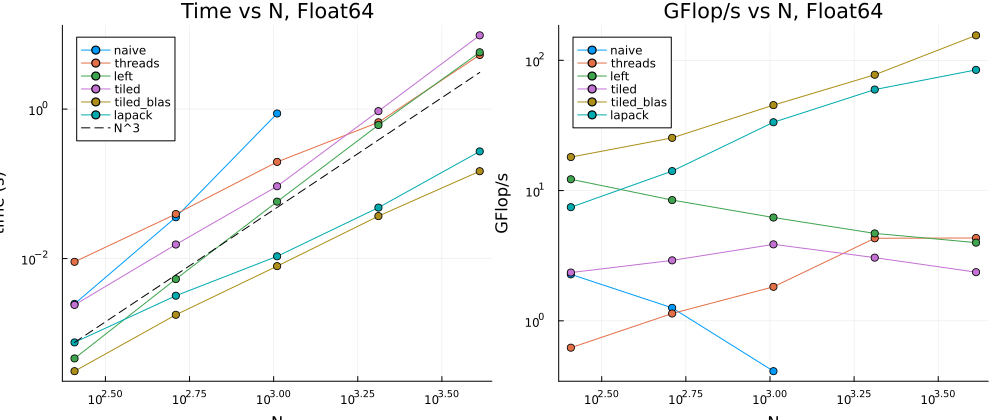

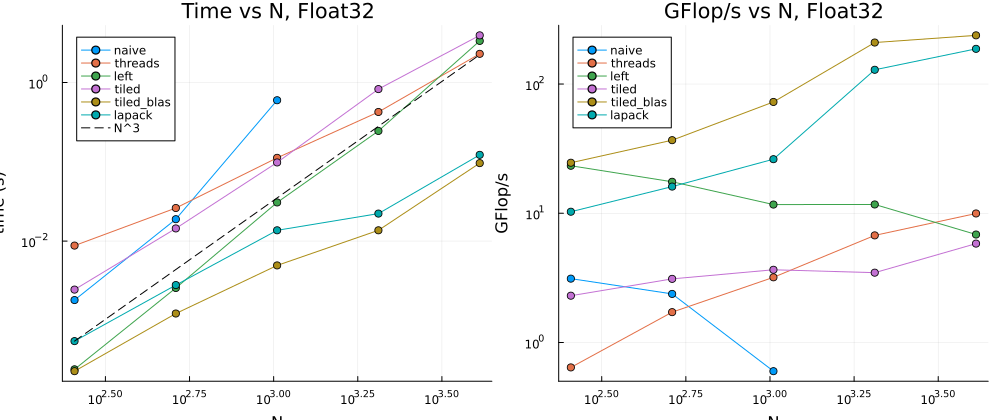


T6_methodology: Factorization timings use bench with a small warm-up and the minimum of 3 repetitions; input copying and solution validation are outside the timed interval.
The Julia worker count is 12; LAPACK uses the restored BLAS setting of 6 threads, whereas tiled_blas temporarily sets BLAS to one thread per call and restores the setting afterwards.
The exported threads column records available Julia threads, not active workers for every implementation: naive and left are sequential, and LAPACK uses its own BLAS pool.
Each row is checked for backward error, but minimum-only timings provide no dispersion estimate and the notebook does not record background load, CPU affinity or clocks, so small differences and hardware causes should be interpreted cautiously.


T6_observations: In Float64, tiled_blas is fastest at N = 256 and tiled_blas at N = 4096 (155.39 GFlop/s); the plots and report card give the intermediate-size winners and the separate Float32 results.
LAPACK increases from 

In [309]:
# TODO · Task 6.2
loglog_slope(ns, ts) = ([ones(length(ns)) log.(ns)] \ log.(ts))[2]      # PROVIDED: least-squares slope of log t vs log N
# rows64 = filter(r -> r.precision == "Float64", BENCH)
# slopes = Dict(name => loglog_slope([r.N for r in rows if r.impl == name], [r.time_s for r in rows if r.impl == name]) for name in …)
# if HAS_PLOTS … plot(…; xscale = :log10, yscale = :log10) … end
# record!("T6_slope", slopes); record!("T6_best", …)
ANSWERS["T6_methodology"] = ""   # how did you make the measurements fair and repeatable (warm-up, min of reps, threads, other load)?
ANSWERS["T6_observations"] = ""  # where do the curves cross, where does GFlop/s plateau or drop, and why (cache sizes, parallel overhead)?

rows64 = filter(r -> r.precision == "Float64", BENCH)
impl_names = [name for (name, _) in IMPLS if any(r -> r.impl == name, BENCH)]

for prec in ("Float64", "Float32")
    println("\nGFlop/s, ", prec)
    println(rpad("impl", 12), join([lpad("N=$n", 10) for n in SIZES]))
    for name in impl_names
        line = rpad(name, 12)
        for n in SIZES
            r = filter(r -> r.impl == name && r.precision == prec && r.N == n, BENCH)
            line *= isempty(r) ? lpad("-", 10) : lpad(@sprintf("%.2f", r[1].gflops), 10)
        end
        println(line)
    end
end

slopes = Dict{String,Float64}()
for name in impl_names
    rr = sort(filter(r -> r.impl == name, rows64); by = r -> r.N)
    rr = rr[max(1, end - 2):end]
    length(rr) >= 2 && (slopes[name] = loglog_slope([r.N for r in rr], [r.time_s for r in rr]))
end
println("\nslope s (t ~ N^s), Float64:")
for name in impl_names
    haskey(slopes, name) && @printf("  %-10s %.2f\n", name, slopes[name])
end

N6 = maximum(r.N for r in rows64)
rows_big = filter(r -> r.N == N6, rows64)
best_row = rows_big[argmin([r.time_s for r in rows_big])]
println("\nfastest at N = $N6 (Float64): ", best_row.impl, @sprintf(" (%.3f s, %.2f GFlop/s)\n", best_row.time_s, best_row.gflops))

record!("T6_slope", slopes)
record!("T6_best", best_row.impl)

if HAS_PLOTS
    for prec in ("Float64", "Float32")
        rows_p = filter(r -> r.precision == prec, BENCH)
        pt = plot(; xscale = :log10, yscale = :log10, xlabel = "N", ylabel = "time (s)",
                  title = "Time vs N, $prec", legend = :topleft)
        pg = plot(; xscale = :log10, yscale = :log10, xlabel = "N", ylabel = "GFlop/s",
                  title = "GFlop/s vs N, $prec", legend = :topleft)
        for name in impl_names
            rr = sort(filter(r -> r.impl == name, rows_p); by = r -> r.N)
            isempty(rr) && continue
            plot!(pt, [r.N for r in rr], [r.time_s for r in rr]; marker = :circle, label = name)
            plot!(pg, [r.N for r in rr], [r.gflops for r in rr]; marker = :circle, label = name)
        end
        r0 = first(sort(filter(r -> r.impl == "lapack", rows_p); by = r -> r.N))
        plot!(pt, SIZES, r0.time_s .* (SIZES ./ r0.N) .^ 3; ls = :dash, color = :black, label = "N^3")
        display(plot(pt, pg; layout = (1, 2), size = (1000, 420)))
    end
end

gf(name, n; prec = "Float64") = (r = filter(r -> r.impl == name && r.N == n && r.precision == prec, BENCH); isempty(r) ? NaN : r[1].gflops)
fastest_at(n) = (rr = filter(r -> r.N == n, rows64); rr[argmin([r.time_s for r in rr])].impl)
N_small = minimum(SIZES)
N_naive = maximum(r.N for r in rows64 if r.impl == "naive")
lapack_gf_max, i_lapack_max = findmax([gf("lapack", n) for n in SIZES])
s_values = collect(values(slopes))
low_s = sort([k for (k, s) in slopes if s < 2.5])

slope_text = "Slopes are fitted over each implementation's three largest available Float64 sizes (the naive fit stops at NAIVE_MAX_N). " *
    (isempty(low_s) ? "" : "For $(join(low_s, ", ")), slopes below 2.5 reflect rising measured throughput over this finite range, not subcubic arithmetic complexity. ") *
    "Slopes above 3 reflect falling throughput; cache behavior and timing variability can contribute, but no cache-miss counters were collected."
out_of_range = sort([k for (k, s) in slopes if !(1.5 <= s <= 4.0)])
if !QUICK && !isempty(out_of_range)
    slope_text *= " The supplied plausibility check fails for $(join(out_of_range, ", ")); the measured slopes are retained without clipping or selecting different points to pass the check."
end
ANSWERS["T6_methodology"] = @sprintf("""
Factorization timings use bench with a small warm-up and the minimum of %d repetitions; input copying and solution validation are outside the timed interval.
The Julia worker count is %d; LAPACK uses the restored BLAS setting of %d threads, whereas tiled_blas temporarily sets BLAS to one thread per call and restores the setting afterwards.
The exported threads column records available Julia threads, not active workers for every implementation: naive and left are sequential, and LAPACK uses its own BLAS pool.
Each row is checked for backward error, but minimum-only timings provide no dispersion estimate and the notebook does not record background load, CPU affinity or clocks, so small differences and hardware causes should be interpreted cautiously.
""", REPS, nthreads(), BLAS_THREADS0)
ANSWERS["T6_observations"] = @sprintf("""
In Float64, %s is fastest at N = %d and %s at N = %d (%.2f GFlop/s); the plots and report card give the intermediate-size winners and the separate Float32 results.
LAPACK increases from %.2f GFlop/s at N = %d to a maximum of %.2f at N = %d, while naive reaches %.2f at its largest tested N = %d; the naive matrix is %.1f MiB, so a claim that it necessarily exceeds the entire last-level cache would be unjustified.
The fitted exponents range from %.2f to %.2f. %s
""", fastest_at(N_small), N_small, best_row.impl, N6, best_row.gflops,
     gf("lapack", N_small), N_small, lapack_gf_max, SIZES[i_lapack_max], gf("naive", N_naive), N_naive,
     8N_naive^2/2.0^20, minimum(s_values), maximum(s_values), slope_text)
println("\nT6_methodology: ", ANSWERS["T6_methodology"])
println("\nT6_observations: ", ANSWERS["T6_observations"])

In [310]:
# CHECK · Chapter 6
_BENCH_KEYS = (:impl, :precision, :N, :time_s, :gflops, :backward_error)
_EPS = Dict("Float64" => eps(Float64), "Float32" => eps(Float32), "Float16" => eps(Float16))
check("T6 BENCH rows follow the schema", () -> !isempty(BENCH) && all(r -> all(haskey(r, k) for k in _BENCH_KEYS), BENCH); points = 2)
check("T6 coverage: ≥ 4 implementations × ≥ 3 sizes × Float64 & Float32",
      () -> length(unique(r.impl for r in BENCH)) >= 4 && length(unique(r.N for r in BENCH)) >= 3 &&
            issubset(["Float64", "Float32"], unique(r.precision for r in BENCH)); points = 2)
check("T6 every benchmarked run passes the backward-error test",
      () -> all(r -> r.backward_error <= 10 * r.N * get(_EPS, r.precision, eps(Float16)), BENCH); points = 1)
# small QUICK sizes are dominated by overheads, so the exponent is only range-checked in a full run
check("T6 scaling exponents recorded" * (QUICK ? "" : " and plausible (1.5 ≤ s ≤ 4)"),
      () -> haskey(RESULTS, "T6_slope") && !isempty(RESULTS["T6_slope"]) &&
            all(s -> isfinite(s) && (QUICK || 1.5 <= s <= 4.0), values(RESULTS["T6_slope"])); points = 1)

✅ T6 BENCH rows follow the schema  [2 pt]
✅ T6 coverage: ≥ 4 implementations × ≥ 3 sizes × Float64 & Float32  [2 pt]
✅ T6 every benchmarked run passes the backward-error test  [1 pt]
❌ T6 scaling exponents recorded and plausible (1.5 ≤ s ≤ 4)  [1 pt]


false

> *Plot twist:* LAPACK reaches some number X of GFlop/s. Is that good? Without knowing what the machine *could* do, X means nothing.

---
# Chapter 7 · The roofline model — *How far from the ceiling?* (14 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 7</b><br>The roofline model says that a kernel with <b>arithmetic intensity</b> I (flop per byte moved from memory) can reach at most <b>min(P<sub>peak</sub>, I × B<sub>mem</sub>)</b>. Measure the two ceilings of your machine, estimate I for each implementation, and place your measured points on the chart. Each point is then either <i>memory-bound</i> or <i>compute-bound</i>, and the gap to its roof tells you how much there is still to gain.</div>

In [311]:
# PROVIDED · roofline model and plot
roofline(ai, peak, bw) = min(peak, ai * bw)      # attainable GFlop/s at intensity ai (flop/byte), bw in GB/s

"plot_roofline(peak, bw, Dict(name => (ai, achieved_gflops))) — prints a table, and plots if Plots.jl is available."
function plot_roofline(peak, bw, points::AbstractDict)
    ridge = peak / bw
    @printf("peak = %.1f GFlop/s | bandwidth = %.1f GB/s | ridge point = %.2f flop/byte\n", peak, bw, ridge)
    for (name, (ai, g)) in points
        roof = roofline(ai, peak, bw)
        @printf("  %-12s AI = %8.3f  achieved = %8.2f  roof = %8.2f GFlop/s  (%5.1f%% of roof, %s-bound)\n",
                name, ai, g, roof, 100 * g / roof, ai < ridge ? "memory" : "compute")
    end
    HAS_PLOTS || return nothing
    ais = 10.0 .^ range(-3, 3; length = 300)
    p = plot(ais, roofline.(ais, peak, bw); xscale = :log10, yscale = :log10, lw = 3, color = :black, label = "roofline",
             xlabel = "arithmetic intensity (flop/byte)", ylabel = "GFlop/s", title = "Roofline — Cholesky implementations",
             legend = :bottomright)
    vline!(p, [ridge]; ls = :dash, color = :gray, label = "ridge point")
    for (name, (ai, g)) in points
        scatter!(p, [ai], [g]; ms = 7, label = name)
    end
    return p
end

plot_roofline (generic function with 1 method)

### Task 7.1 · The two ceilings
* **Memory bandwidth:** implement the STREAM triad $a_i = b_i + s\,c_i$ on Float64 vectors much larger than the last-level cache, parallelized with `Threads.@threads`. Count $3 \cdot 8n$ bytes per sweep and return the best rate in GB/s.
* **Peak compute:** measured as the GFlop/s of a large `BLAS.gemm!` ($2n^3$ flops) with all BLAS threads; theoretical from the CPU spec sheet as cores × GHz × SIMD lanes × 2 (FMA) × FMA units.

**Hardware model sources.** [Intel i7-1355U specifications](https://www.intel.com/content/www/us/en/products/compare.html?productIds=232153%2C232160) give 2 P-cores, 8 E-cores, 12 threads and maximum P/E turbo frequencies of 5.0/3.7 GHz. The [Intel Optimization Reference Manual](https://www.intel.com/content/www/us/en/developer/articles/technical/intel64-and-ia32-architectures-optimization.html) describes the Golden Cove and Gracemont execution units used in the FP64 model. Adding the per-core turbo capacities gives an optimistic upper bound; simultaneous sustained clocks and power limits are not measured.

In [312]:
# TODO · Task 7.1
"Threaded STREAM triad kernel: a = b + s*c."
function _triad!(a::Vector{Float64}, b::Vector{Float64}, c::Vector{Float64}, s::Float64)
    Threads.@threads :static for i in eachindex(a)
        @inbounds a[i] = b[i] + s * c[i]
    end
    return a
end

"stream_triad_bw(; n, reps = 5) -> GB/s (best of reps), threaded STREAM triad (3 vectors of n Float64)."
function stream_triad_bw(; n::Int = QUICK ? 2^22 : 2^24, reps::Int = 5)
    a = Vector{Float64}(undef, n); b = Vector{Float64}(undef, n); c = Vector{Float64}(undef, n)
    Threads.@threads :static for i in 1:n      # first touch by the threads that will use the data
        @inbounds begin
            a[i] = 0.0; b[i] = 1.0; c[i] = 2.0
        end
    end
    _triad!(a, b, c, 3.0)                       # warm-up (compilation)
    best = Inf
    for _ in 1:reps
        best = min(best, @elapsed _triad!(a, b, c, 3.0))
    end
    return 3 * 8 * n / best / 1e9               # read b, read c, write a
end

"Measured compute peak: GFlop/s of a large BLAS.gemm! with all BLAS threads."
function gemm_peak_gflops(; n::Int = QUICK ? 1024 : 4096, reps::Int = 3)
    X = rand(n, n); Y = rand(n, n); Z = zeros(n, n)
    best = Inf
    try
        BLAS.set_num_threads(max(BLAS_THREADS0, Sys.CPU_THREADS))
        BLAS.gemm!('N', 'N', 1.0, X, Y, 0.0, Z)                 # warm-up
        for _ in 1:reps
            best = min(best, @elapsed BLAS.gemm!('N', 'N', 1.0, X, Y, 0.0, Z))
        end
    finally
        BLAS.set_num_threads(BLAS_THREADS0)
    end
    return 2.0 * n^3 / best / 1e9
end


# Theoretical FP64 FMA ceiling for the machine used in this submission.
# Intel i7-1355U: 2 P-cores + 8 E-cores (12 hardware threads are not 12 cores).
# P-core: 2 x 256-bit FMA pipelines => 16 FP64 flop/cycle.
# E-core: 2 x 128-bit FMA pipelines => 8 FP64 flop/cycle.
# Per-core maximum turbo frequencies give an optimistic upper bound, not
# simultaneous sustained all-core frequencies on this power-limited laptop.
# Sources: Intel i7-1355U specifications and Intel Optimization Manual,
# Golden Cove and Gracemont execution-unit descriptions (linked below).
PEAK_FORMULA = "2 P-cores x 5.0 GHz x 4 FP64 lanes x 2 (FMA) x 2 units + 8 E-cores x 3.7 GHz x 2 FP64 lanes x 2 (FMA) x 2 units"
PEAK_GFLOPS_THEORY = 2 * 5.0 * 4 * 2 * 2 + 8 * 3.7 * 2 * 2 * 2
if !occursin("i7-1355U", Sys.cpu_info()[1].model)
    @warn "The theoretical model is for the submission's i7-1355U; replace the hardware parameters when running on another CPU."
end
PEAK_BW = stream_triad_bw()
PEAK_GFLOPS = gemm_peak_gflops()
@printf("STREAM triad bandwidth : %.2f GB/s\n", PEAK_BW)
@printf("Measured FP64 GEMM rate: %.2f GFlop/s\n", PEAK_GFLOPS)
@printf("Theoretical turbo upper bound: %.2f GFlop/s\n%s\n", PEAK_GFLOPS_THEORY, PEAK_FORMULA)
@printf("Ridge point: %.2f flop/byte | GEMM / turbo bound: %.1f%%\n", PEAK_GFLOPS / PEAK_BW, 100PEAK_GFLOPS/PEAK_GFLOPS_THEORY)
record!("T7_bandwidth_GBs", PEAK_BW)
record!("T7_peak_gflops", PEAK_GFLOPS)
record!("T7_peak_gflops_theory", PEAK_GFLOPS_THEORY)
record!("T7_ridge_point", PEAK_GFLOPS/PEAK_BW)
record!("T7_peak_formula", PEAK_FORMULA)
# Refresh Chapter 4's bandwidth comparison using this run's measured ceiling.
refresh_person_a_answers!()

STREAM triad bandwidth : 30.02 GB/s
Measured FP64 GEMM rate: 107.12 GFlop/s
Theoretical turbo upper bound: 396.80 GFlop/s
2 P-cores x 5.0 GHz x 4 FP64 lanes x 2 (FMA) x 2 units + 8 E-cores x 3.7 GHz x 2 FP64 lanes x 2 (FMA) x 2 units
Ridge point: 3.57 flop/byte | GEMM / turbo bound: 27.0%
T4_traffic:     For N = 1024, the naive dot products contain Q = N(N-1)(N+1)/6 = 178956800 multiply-adds; two Float64 loads per term give 16Q = 2863308800 modeled bytes 
    and 2.849 GB/s when divided by the measured time 1.005107 s. Left-looking took 0.039241 s (a naive/left time ratio of 25.614), 
    and its contiguous i-loop enables SIMD, prefetching and reuse of the active column. Its update operands involve two loads 
    and one store per element without reuse, but caches can avoid much of this DRAM traffic, so operand counts alone do not predict bandwidth.     The modeled rate is 0.095x the measured STREAM bandwidth of 30.021 GB/s; differences reflect the model assumptions and cache 
    reus

### Task 7.2 · Arithmetic intensity and the roofline chart
1. Estimate the arithmetic intensity (flop per byte from **memory**, for Float64) of each implementation. For example: the naive inner loop does 2 flops per two loaded Float64 values (16 B) if nothing stays in cache; a GEMM on $nb \times nb$ tiles does $2nb^3$ flops on $3nb^2 \cdot 8$ B.
2. Use `plot_roofline(PEAK_GFLOPS, PEAK_BW, Dict(name => (ARITH_INTENSITY[name], achieved GFlop/s at your largest N from BENCH)))`.
3. Fill `BOUND[name] = "memory"` or `"compute"` according to the model, meaning which side of the ridge point it sits on.
4. `record!("T7_fraction_of_roof", Dict(name => achieved / roof))`.


peak = 107.1 GFlop/s | bandwidth = 30.0 GB/s | ridge point = 3.57 flop/byte
  lapack       AI =  170.667  achieved =    84.43  roof =   107.12 GFlop/s  ( 78.8% of roof, compute-bound)
  tiled        AI =    5.333  achieved =     2.36  roof =   107.12 GFlop/s  (  2.2% of roof, compute-bound)
  naive        AI =    0.125  achieved =     0.41  roof =     3.75 GFlop/s  ( 10.9% of roof, memory-bound)
  tiled_blas   AI =   10.667  achieved =   155.39  roof =   107.12 GFlop/s  (145.1% of roof, compute-bound)
  threads      AI =    0.083  achieved =     4.32  roof =     2.50 GFlop/s  (172.9% of roof, memory-bound)
  left         AI =    0.250  achieved =     3.98  roof =     7.51 GFlop/s  ( 53.1% of roof, memory-bound)


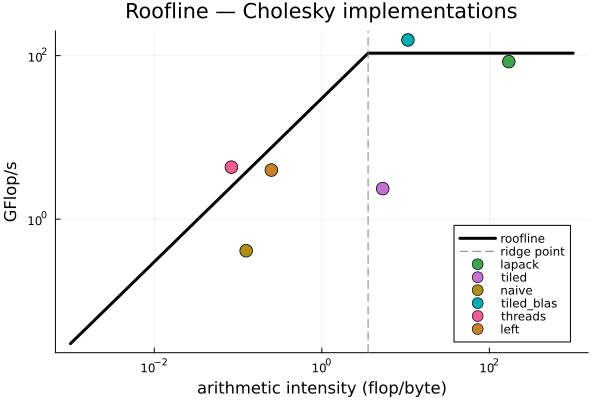

T7_ai_derivation: These are approximate Float64 traffic models, not measured DRAM intensities: naive uses 2/16 = 0.125 flop/B with no operand reuse, threads uses 2/24 = 0.083 with two loads and one store, and left uses 2/8 = 0.25 assuming its destination column remains cached.
Following the assignment's three-tile working-set estimate, tiled and tiled_blas use nb/12 = 5.333 and 10.667 flop/B; counting separate reads and writes of the destination tile instead gives nb/16, so the three-tile estimate is optimistic and does not describe the row-oriented loop kernel's actual transfers.
LAPACK uses N/24 = 170.667 at N = 4096 as an idealized lower-triangle read/write-once bound; finite cache capacity and repeated panel traffic can lower its actual intensity, and naive is plotted at its largest measured size N = 1024 while the other points use N = 4096.
The theoretical turbo ceiling is 2 P-cores x 5.0 GHz x 4 FP64 lanes x 2 (FMA) x 2 units + 8 E-cores x 3.7 GHz x 2 FP64 lanes x 2 (FMA) x 2 uni

In [313]:
# TODO · Task 7.2
ARITH_INTENSITY = Dict{String,Float64}(
    # "naive"      => …,
    # "left"       => …,
    # "tiled"      => …,
    # "tiled_blas" => …,
    # "lapack"     => …,
)
BOUND = Dict{String,String}()        # name => "memory" | "compute"
# plot_roofline(PEAK_GFLOPS, PEAK_BW, Dict(name => (ARITH_INTENSITY[name], …) for name in keys(ARITH_INTENSITY)))
# record!("T7_fraction_of_roof", …)
ANSWERS["T7_ai_derivation"]  = ""   # how you derived each intensity and the theoretical peak
ANSWERS["T7_interpretation"] = ""   # which implementations are memory- vs compute-bound, how far each is from its roof, what would move it up

N7 = maximum(r.N for r in rows64)
ai_model = Dict("naive" => 2 / 16, "threads" => 2 / 24, "left" => 2 / 8,
                "tiled" => BEST_NB / 12, "tiled_blas" => BEST_NB_BLAS / 12, "lapack" => N7 / 24)

achieved = Dict{String,Float64}()
for name in impl_names
    haskey(ai_model, name) || continue
    rr = filter(r -> r.impl == name, rows64)
    ARITH_INTENSITY[name] = ai_model[name]
    achieved[name] = rr[argmax([r.N for r in rr])].gflops
end

for name in keys(ARITH_INTENSITY)
    BOUND[name] = ARITH_INTENSITY[name] * PEAK_BW < PEAK_GFLOPS ? "memory" : "compute"
end
println()

frac_roof = Dict(name => achieved[name] / roofline(ARITH_INTENSITY[name], PEAK_GFLOPS, PEAK_BW) for name in keys(ARITH_INTENSITY))
p7 = plot_roofline(PEAK_GFLOPS, PEAK_BW, Dict(name => (ARITH_INTENSITY[name], achieved[name]) for name in keys(ARITH_INTENSITY)))
p7 === nothing || display(p7)

record!("T7_fraction_of_roof", frac_roof)
record!("T7_arith_intensity", ARITH_INTENSITY)


ANSWERS["T7_ai_derivation"] = @sprintf("""
These are approximate Float64 traffic models, not measured DRAM intensities: naive uses 2/16 = 0.125 flop/B with no operand reuse, threads uses 2/24 = 0.083 with two loads and one store, and left uses 2/8 = 0.25 assuming its destination column remains cached.
Following the assignment's three-tile working-set estimate, tiled and tiled_blas use nb/12 = %.3f and %.3f flop/B; counting separate reads and writes of the destination tile instead gives nb/16, so the three-tile estimate is optimistic and does not describe the row-oriented loop kernel's actual transfers.
LAPACK uses N/24 = %.3f at N = %d as an idealized lower-triangle read/write-once bound; finite cache capacity and repeated panel traffic can lower its actual intensity, and naive is plotted at its largest measured size N = %d while the other points use N = %d.
The theoretical turbo ceiling is %s = %.1f GFlop/s (physical P/E cores counted separately); the measured FP64 GEMM rate is the empirical compute reference, not a guaranteed hardware maximum.
""", BEST_NB/12, BEST_NB_BLAS/12, N7/24, N7, N_naive, N7,
     RESULTS["T7_peak_formula"], PEAK_GFLOPS_THEORY)
mem_names = sort([k for k in keys(BOUND) if BOUND[k] == "memory"])
comp_names = sort([k for k in keys(BOUND) if BOUND[k] == "compute"])
pct(names) = join([@sprintf("%s %.1f%%", k, 100frac_roof[k]) for k in names], ", ")
over_roof = sort([k for k in keys(frac_roof) if frac_roof[k] > 1])
over_text = isempty(over_roof) ? "No measured point exceeds its modeled roof." :
    "$(join(over_roof, ", ")) exceeds its modeled roof, exposing limitations of the assumed traffic or empirical ceilings; cached operands, differing thread configurations and timing variability can contribute."
ANSWERS["T7_interpretation"] = @sprintf("""
With bandwidth %.2f GB/s and an FP64 GEMM reference of %.2f GFlop/s, the ridge is %.3f flop/B; the model classifies %s on the memory side and %s on the compute side.
Fractions of the modeled roof are memory side: %s; compute side: %s. %s
These labels identify the limiting term of the model, not a proven runtime bottleneck: better SIMD use, fewer bounds checks, improved scheduling and more effective bandwidth use can raise a point without changing its modeled intensity, while blocking can also move it right through reuse.
The loop-tiled kernel's low fraction motivates those changes; LAPACK in the sweep uses %d BLAS threads, tiled_blas uses Julia tasks with single-thread BLAS, and GEMM uses %d BLAS threads, so the chart compares configurations as well as algorithms.
""", PEAK_BW, PEAK_GFLOPS, PEAK_GFLOPS/PEAK_BW, join(mem_names, ", "), join(comp_names, ", "),
     pct(mem_names), pct(comp_names), over_text, BLAS_THREADS0, max(BLAS_THREADS0, Sys.CPU_THREADS))
println("T7_ai_derivation: ", ANSWERS["T7_ai_derivation"])
println("\nT7_interpretation: ", ANSWERS["T7_interpretation"])

In [314]:
# CHECK · Chapter 7
check("T7 memory bandwidth measured and plausible (1–3000 GB/s)", () -> isfinite(PEAK_BW) && 1 <= PEAK_BW <= 3000; points = 1)
check("T7 peak GFlop/s measured and plausible", () -> isfinite(PEAK_GFLOPS) && 1 <= PEAK_GFLOPS <= 1e5 && isfinite(PEAK_GFLOPS_THEORY); points = 1)
check("T7 arithmetic intensity for ≥ 4 implementations", () -> length(ARITH_INTENSITY) >= 4 && all(v -> 0 < v < 1e4, values(ARITH_INTENSITY)); points = 1)
check("T7 bounds consistent with the ridge point",
      () -> length(BOUND) >= 4 && all(k -> BOUND[k] == (ARITH_INTENSITY[k] * PEAK_BW < PEAK_GFLOPS ? "memory" : "compute"), keys(BOUND)); points = 2)

✅ T7 memory bandwidth measured and plausible (1–3000 GB/s)  [1 pt]
✅ T7 peak GFlop/s measured and plausible  [1 pt]
✅ T7 arithmetic intensity for ≥ 4 implementations  [1 pt]
✅ T7 bounds consistent with the ridge point  [2 pt]


true

> *Plot twist:* the numbers are in, the chart is drawn, and the director's meeting is on Friday.

---
# Chapter 8 · Report card & conclusions — *Briefing the director* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 8</b><br>Friday afternoon. The director has five minutes and one question: <i>"Which solver do we deploy, how fast is it, and can we trust it?"</i> Answer on one page, with numbers.</div>

## Performance report card

The rendered table below is generated directly from this run's `RESULTS` and `BENCH`. All benchmark times measure **factorization only** unless explicitly labeled as complete solves. Chapter 3 precision and refinement results use the loop-tiled kernel at the single-experiment size; they are not measurements of vendor mixed precision at N = 4096.

In [315]:
# TODO · Task 8
rec = best_row
rec32 = only(filter(r -> r.impl == rec.impl && r.N == rec.N && r.precision == "Float32", BENCH))
lap_rec = only(filter(r -> r.impl == "lapack" && r.N == rec.N && r.precision == "Float64", BENCH))
f32_speedup = rec.time_s / rec32.time_s
digits_lost = log10(RESULTS["T3_backward_errors"]["Float32"] / RESULTS["T3_backward_errors"]["Float64"])
ir_speedup = RESULTS["T3_float64_total_time"] / RESULTS["T3_ir_time"]
ANSWERS["T8_recommendation"] = @sprintf("""
For hourly systems near N = 4000, the measured choice is %s in Float64: at N = %d its factorization takes %.4f s (%.2f GFlop/s), versus %.4f s for LAPACK with %d BLAS threads, and its solved-system backward error is %.3e against the %.3e acceptance limit.
This factorization fits comfortably within an hour, but covariance construction and complete application latency are not timed here; the custom tile scheduler also needs maintenance, while one LAPACK call remains the simpler alternative.
At the same N, this implementation in Float32 takes %.4f s (%.2fx faster) with backward error %.3e, so precision should be selected against application accuracy requirements, not just sensor decimal digits.
Mixed IR was tested only with loop tiles at N = %d and gave a %.3fx Float64/mixed total-time ratio; benchmark vendor Float32 plus refinement at the deployment size, retune tile/BLAS thread counts there, and test representative covariance conditioning before changing this recommendation.
""", rec.impl, rec.N, rec.time_s, rec.gflops, lap_rec.time_s, BLAS_THREADS0,
     rec.backward_error, 10rec.N*eps(Float64), rec32.time_s, f32_speedup, rec32.backward_error, N, ir_speedup)
ANSWERS["T8_conclusions"] = join([
    @sprintf("- Column-level tasks achieved at most %.2fx relative to sequential right-looking; compare this with the tiled sequential/parallel speed-up of %.2fx at N = %d.", RESULTS["T1_speedup_max"], t_seq/t_par, N),
    @sprintf("- Loop tiles selected nb = %d and vendor tiles nb = %d at N = %d; these settings were then reused across the size sweep, not retuned per size.", BEST_NB, BEST_NB_BLAS, N),
    @sprintf("- At the same N = %d, %s takes %.4f s versus LAPACK's %.4f s (%.2fx); better data movement also makes sequential left %.2fx faster than naive in the Chapter 4 comparison.", rec.N, rec.impl, rec.time_s, lap_rec.time_s, lap_rec.time_s/rec.time_s, RESULTS["T4_times"]["naive"]/RESULTS["T4_times"]["left"]),
    @sprintf("- For Chapter 3 loop tiles, Float32 changes backward error by %.2f decades; IR uses %d corrections and reaches eta = %.3e, with total-time speed-up ratio %.3fx.", digits_lost, RESULTS["T3_ir_iters"], RESULTS["T3_ir_backward_error"], ir_speedup),
    "- Next: complete the Chapter 4 tile-kernel optimization comparison, quantify timing variability, and test vendor mixed precision and thread/tile tuning at the deployment size; roofline labels remain model-dependent.",
], "\n")
println("T8_recommendation: ", ANSWERS["T8_recommendation"])
println("\nT8_conclusions:\n", ANSWERS["T8_conclusions"])

T8_recommendation: For hourly systems near N = 4000, the measured choice is tiled_blas in Float64: at N = 4096 its factorization takes 0.1475 s (155.39 GFlop/s), versus 0.2714 s for LAPACK with 6 BLAS threads, and its solved-system backward error is 1.534e-15 against the 9.095e-12 acceptance limit.
This factorization fits comfortably within an hour, but covariance construction and complete application latency are not timed here; the custom tile scheduler also needs maintenance, while one LAPACK call remains the simpler alternative.
At the same N, this implementation in Float32 takes 0.0962 s (1.53x faster) with backward error 1.661e-07, so precision should be selected against application accuracy requirements, not just sensor decimal digits.
Mixed IR was tested only with loop tiles at N = 1024 and gave a 0.389x Float64/mixed total-time ratio; benchmark vendor Float32 plus refinement at the deployment size, retune tile/BLAS thread counts there, and test representative covariance conditi

In [318]:
# TODO · Task 8 — report generated from the current run
t_nv = RESULTS["P_naive_time_s"]
parallel_ps = filter(p -> p > 1, collect(keys(RESULTS["T1_times"])))
parallel_own = Dict{String,Tuple{Float64,Float64,String}}()
if !isempty(parallel_ps)
    p_best = parallel_ps[argmin([RESULTS["T1_times"][p] for p in parallel_ps])]
    tp = RESULTS["T1_times"][p_best]
    parallel_own["threads"] = (tp, RESULTS["T1_times"][1]/tp/p_best, "p = $p_best; efficiency uses this p")
end
if tasks_per_nb[BEST_NB] > 0
    parallel_own["tiled"] = (t_par, t_seq/t_par/nthreads(), "nb = $BEST_NB; efficiency uses $(nthreads()) Julia threads")
end
parallel_text = if isempty(parallel_own)
    "No configuration with spawned tasks is available."
else
    name, (t, eff, config) = first(sort(collect(parallel_own); by = kv -> kv[2][1]))
    @sprintf("%s (%s): %.4f s, %.2f GFlop/s, %.2fx over Chapter 0; efficiency %.1f%% relative to the same algorithm's sequential time.",
             name, config, t, gflops(chol_flops(N), t), t_nv/t, 100eff)
end
by_size_summary(prec) = join([begin
    rr = filter(r -> r.N == n && r.precision == prec, BENCH)
    r = rr[argmin([r.time_s for r in rr])]
    @sprintf("N=%d: %s, %.6f s / %.2f GFlop/s", n, r.impl, r.time_s, r.gflops)
end for n in SIZES], "<br>")
lap_gf = gflops(chol_flops(N), t_ref)
t4 = RESULTS["T4_times"]
hardware = occursin("i7-1355U", Sys.cpu_info()[1].model) ? "10 physical cores (2 P + 8 E), " : ""
failed_checks = sort([k for (k,v) in CHECKS if !v["pass"]])
card = [
    ("Hardware", "$(Sys.cpu_info()[1].model); $(hardware)$(Sys.CPU_THREADS) logical CPUs; Julia $(VERSION), $(nthreads()) Julia threads; $(BLAS.get_config()). Default BLAS: $(BLAS_THREADS0); tile tasks: BLAS 1; Chapter 5 comparison: 1 and $(NALL); GEMM: $(NALL)."),
    ("Baseline (Chapter 0)", @sprintf("N=%d: %.6f s, %.3f GFlop/s.", N, t_nv, RESULTS["P_naive_gflops"])),
    ("Best measured parallel loop version at N", parallel_text),
    ("Sequential data-movement comparison (Chapter 4)", @sprintf("naive %.6f s → left %.6f s (%.2fx); both allocate %d / %d bytes. Threaded and tiled variants allocate %d / %d bytes, chiefly task overhead; no before/after optimized tile-kernel experiment is recorded.", t4["naive"], t4["left"], t4["naive"]/t4["left"], RESULTS["T4_allocations"]["naive"], RESULTS["T4_allocations"]["left"], RESULTS["T4_allocations"]["threads"], RESULTS["T4_allocations"]["tiled"])),
    ("Best granularity", @sprintf("At N=%d: loop nb=%d; BLAS nb=%d. Loop optimum balances task overhead, concurrency and locality. Three nb=%d Float64 tiles occupy %d bytes; the smallest detected L2 domain is %d bytes. Size sweep reuses these tile sizes.", N, BEST_NB, BEST_NB_BLAS, BEST_NB, 24BEST_NB^2, RESULTS["T4_L2_model_bytes"])),
    ("Precision / complete mixed solve (Chapter 3)", @sprintf("Loop tiles at N=%d: Float64/Float32 factorization-time ratio %.3fx; backward/forward error increases %.2f / %.2f decades. IR: %d corrections, eta=%.3e; %.6f s versus Float64 %.6f s (ratio %.3fx).", N, t64/t32, log10(η32/η64), log10(fe32/fe64), RESULTS["T3_ir_iters"], RESULTS["T3_ir_backward_error"], t_ir, t_float64, ir_speedup)),
    ("Vendor comparison (Chapter 5)", @sprintf("At N=%d: faster LAPACK setting %.2f GFlop/s (%.1f%% of measured FP64 GEMM); best loop in the same comparison (%s) %.1f%% of LAPACK; tiled_blas %.1f%%. LAPACK: 1 thread %.3f ms; %d threads %.3f ms.", N, lap_gf, 100lap_gf/PEAK_GFLOPS, _best_own_name, _best_own_pct, 100t_ref/t5["tiled_blas"], 1000t5["lapack_1thread"], NALL, 1000t5["lapack_all"])),
    ("Benchmark winners — Float64 (time / throughput)", by_size_summary("Float64")),
    ("Benchmark winners — Float32 (time / throughput)", by_size_summary("Float32")),
    ("Roofline", @sprintf("STREAM %.2f GB/s; FP64 GEMM %.2f GFlop/s; ridge %.3f flop/B. Model memory side: %s; compute side: %s. %s Naive point uses N=%d; others N=%d. Theoretical turbo upper bound %.1f GFlop/s; sustained frequency was not measured.", PEAK_BW, PEAK_GFLOPS, PEAK_GFLOPS/PEAK_BW, pct(mem_names), pct(comp_names), over_text, N_naive, N7, PEAK_GFLOPS_THEORY)),
    ("Accuracy at deployment size", @sprintf("N=%d, %s: Float64 eta=%.3e (limit %.3e); Float32 eta=%.3e. Chapter 3 IR accuracy above is from N=%d with loop tiles, not vendor IR at this size.", rec.N, rec.impl, rec.backward_error, 10rec.N*eps(Float64), rec32.backward_error, N)),
    ("Recommendation", @sprintf("%s, Float64: %.4f s factorization at N=%d (%.2f GFlop/s); LAPACK %.4f s is a simpler maintenance alternative. Full application latency is not measured.", rec.impl, rec.time_s, rec.N, rec.gflops, lap_rec.time_s)),
    ("Key conclusions", replace(ANSWERS["T8_conclusions"], "\n" => "<br>")),
    ("Checks so far", isempty(failed_checks) ? "All preceding checks pass; this is not a guarantee of hidden-test results or complete rubric coverage." : "Unresolved: " * join(failed_checks, "; ") * ". Retain the measured result and investigate it before submission."),
]
card_md = "| Item | Result |\n|---|---|\n" * join(["| $item | $(replace(txt, "|" => "/", "\n" => " ")) |" for (item,txt) in card], "\n")
display(MIME"text/markdown"(), card_md)

| Item | Result |
|---|---|
| Hardware | 13th Gen Intel(R) Core(TM) i7-1355U; 10 physical cores (2 P + 8 E), 12 logical CPUs; Julia 1.13.2, 12 Julia threads; LBTConfig([ILP64] libopenblas64_.dll). Default BLAS: 6; tile tasks: BLAS 1; Chapter 5 comparison: 1 and 12; GEMM: 12. |
| Baseline (Chapter 0) | N=1024: 0.726244 s, 0.494 GFlop/s. |
| Best measured parallel loop version at N | tiled (nb = 64; efficiency uses 12 Julia threads): 0.0655 s, 5.48 GFlop/s, 11.10x over Chapter 0; efficiency 24.1% relative to the same algorithm's sequential time. |
| Sequential data-movement comparison (Chapter 4) | naive 1.005107 s → left 0.039241 s (25.61x); both allocate 0 / 0 bytes. Threaded and tiled variants allocate 5292848 / 472096 bytes, chiefly task overhead; no before/after optimized tile-kernel experiment is recorded. |
| Best granularity | At N=1024: loop nb=64; BLAS nb=128. Loop optimum balances task overhead, concurrency and locality. Three nb=64 Float64 tiles occupy 98304 bytes; the smallest detected L2 domain is 1310720 bytes. Size sweep reuses these tile sizes. |
| Precision / complete mixed solve (Chapter 3) | Loop tiles at N=1024: Float64/Float32 factorization-time ratio 0.963x; backward/forward error increases 8.95 / 8.81 decades. IR: 10 corrections, eta=7.705e-16; 0.209376 s versus Float64 0.081381 s (ratio 0.389x). |
| Vendor comparison (Chapter 5) | At N=1024: faster LAPACK setting 40.29 GFlop/s (37.6% of measured FP64 GEMM); best loop in the same comparison (left) 13.0% of LAPACK; tiled_blas 142.9%. LAPACK: 1 thread 9.534 ms; 12 threads 8.897 ms. |
| Benchmark winners — Float64 (time / throughput) | N=256: tiled_blas, 0.000311 s / 18.08 GFlop/s<br>N=512: tiled_blas, 0.001768 s / 25.38 GFlop/s<br>N=1024: tiled_blas, 0.007915 s / 45.28 GFlop/s<br>N=2048: tiled_blas, 0.037000 s / 77.44 GFlop/s<br>N=4096: tiled_blas, 0.147470 s / 155.39 GFlop/s |
| Benchmark winners — Float32 (time / throughput) | N=256: tiled_blas, 0.000229 s / 24.61 GFlop/s<br>N=512: tiled_blas, 0.001220 s / 36.78 GFlop/s<br>N=1024: tiled_blas, 0.004931 s / 72.69 GFlop/s<br>N=2048: tiled_blas, 0.013674 s / 209.54 GFlop/s<br>N=4096: tiled_blas, 0.096227 s / 238.13 GFlop/s |
| Roofline | STREAM 30.02 GB/s; FP64 GEMM 107.12 GFlop/s; ridge 3.568 flop/B. Model memory side: left 53.1%, naive 10.9%, threads 172.9%; compute side: lapack 78.8%, tiled 2.2%, tiled_blas 145.1%. threads, tiled_blas exceeds its modeled roof, exposing limitations of the assumed traffic or empirical ceilings; cached operands, differing thread configurations and timing variability can contribute. Naive point uses N=1024; others N=4096. Theoretical turbo upper bound 396.8 GFlop/s; sustained frequency was not measured. |
| Accuracy at deployment size | N=4096, tiled_blas: Float64 eta=1.534e-15 (limit 9.095e-12); Float32 eta=1.661e-07. Chapter 3 IR accuracy above is from N=1024 with loop tiles, not vendor IR at this size. |
| Recommendation | tiled_blas, Float64: 0.1475 s factorization at N=4096 (155.39 GFlop/s); LAPACK 0.2714 s is a simpler maintenance alternative. Full application latency is not measured. |
| Key conclusions | - Column-level tasks achieved at most 1.00x relative to sequential right-looking; compare this with the tiled sequential/parallel speed-up of 2.89x at N = 1024.<br>- Loop tiles selected nb = 64 and vendor tiles nb = 128 at N = 1024; these settings were then reused across the size sweep, not retuned per size.<br>- At the same N = 4096, tiled_blas takes 0.1475 s versus LAPACK's 0.2714 s (1.84x); better data movement also makes sequential left 25.61x faster than naive in the Chapter 4 comparison.<br>- For Chapter 3 loop tiles, Float32 changes backward error by 8.95 decades; IR uses 10 corrections and reaches eta = 7.705e-16, with total-time speed-up ratio 0.389x.<br>- Next: complete the Chapter 4 tile-kernel optimization comparison, quantify timing variability, and test vendor mixed precision and thread/tile tuning at the deployment size; roofline labels remain model-dependent. |
| Checks so far | Unresolved: T6 scaling exponents recorded and plausible (1.5 ≤ s ≤ 4). Retain the measured result and investigate it before submission. |

In [319]:
# CHECK · Chapter 8
check("T8 every ANSWERS entry filled (≥ 20 characters)", () -> length(ANSWERS) >= 16 && all(v -> length(strip(v)) >= 20, values(ANSWERS)); points = 1)

✅ T8 every ANSWERS entry filled (≥ 20 characters)  [1 pt]


true

## ★ HPC bonus (+10 pts)
* **A · Task-DAG scheduling:** remove the phase barriers in Chapter 2. Each tile task waits only on the tasks it depends on (spawn tasks that `fetch` their predecessors, or use `Dagger.jl`). Compare with the fork-join version.
* **B · GPU:** `CUDA.jl` / `AMDGPU.jl` / `Metal.jl` — `cholesky` on the device, in Float64 and Float32, including transfer time. At which N does the GPU win?
* **C · Recursive Cholesky:** cache-oblivious recursive splitting into two halves (POTRF, TRSM, SYRK, POTRF). Compare with tiled and LAPACK.
* **D · Distributed memory:** `Distributed.jl` or `MPI.jl` with a 1-D block-cyclic column distribution. Measure strong scaling over processes.

Record your bonus results with `record!("BONUS_…", …)` and describe them in `ANSWERS["BONUS"]`.

In [320]:
# TODO · Bonus (optional)

---
## Export for grading
Run last, after **Kernel → Restart & Run All**. Writes `results_team<ID>.json` (results, answers, checks, benchmark rows, roofline values, environment) and `bench_team<ID>.csv`. Submit them together with the executed notebook.

In [321]:
# PROVIDED · export everything the grader needs
_get(s::Symbol) = isdefined(Main, s) ? getfield(Main, s) : nothing
env = Dict("julia" => string(VERSION), "threads" => nthreads(), "blas_threads" => BLAS.get_num_threads(),
           "blas" => string(BLAS.get_config()), "cpu" => Sys.cpu_info()[1].model, "cpu_threads" => Sys.CPU_THREADS,
           "quick" => QUICK, "N" => N, "sizes" => SIZES, "timestamp" => string(now()))
roof = Dict("peak_gflops" => _get(:PEAK_GFLOPS), "peak_gflops_theory" => _get(:PEAK_GFLOPS_THEORY),
            "bandwidth_GBs" => _get(:PEAK_BW), "arith_intensity" => _get(:ARITH_INTENSITY), "bound" => _get(:BOUND))
out = Dict("team_id" => TEAM_ID, "env" => env, "results" => RESULTS, "answers" => ANSWERS, "checks" => CHECKS,
           "bench" => BENCH, "roofline" => roof,
           "best_nb" => _get(:BEST_NB), "best_nb_blas" => _get(:BEST_NB_BLAS))
fname = "results_team$(TEAM_ID).json"
open(io -> write(io, to_json(out)), fname, "w")
try
    open("bench_team$(TEAM_ID).csv", "w") do io
        println(io, "impl,precision,N,threads,time_s,gflops,backward_error")
        for r in BENCH
            println(io, join((r.impl, r.precision, r.N, r.threads, r.time_s, r.gflops, r.backward_error), ","))
        end
    end
catch err
    @warn "could not write the benchmark CSV" err
end
npass = count(v -> v["pass"], values(CHECKS))
auto  = sum((v["points"] for v in values(CHECKS) if v["pass"]); init = 0)
total = sum((v["points"] for v in values(CHECKS)); init = 0)
@printf("wrote %s | checks passed: %d / %d | automatic points: %g / %g (the other 58 points are read by the instructor)\n",
        fname, npass, length(CHECKS), auto, total)

wrote results_team1013.json | checks passed: 36 / 37 | automatic points: 41 / 42 (the other 58 points are read by the instructor)


<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Hatem Ltaief</div>